# Cảnh báo sớm sinh viên có nguy cơ nghỉ học — Tiểu luận cuối khóa
Dữ liệu UCI "Predict students' dropout and academic success". Chạy: **Restart & Run All** (Colab hoặc máy cá nhân).

In [ ]:
%pip install -q optuna shap ucimlrepo   
from pathlib import Path
import os
_PROJECT_ROOT = Path.cwd().parent if not Path("data").exists() and Path("../data").exists() else Path.cwd()
os.chdir(_PROJECT_ROOT)


Note: you may need to restart the kernel to use updated packages.


In [ ]:
%%writefile dropout_utils.py
"""
dropout_utils.py
Module dùng chung cho notebook tiểu luận và app Streamlit.
Giữ ở cùng thư mục với notebook và app.py.

Nội dung:
  - load_data(): đọc bộ UCI "Predict students' dropout and academic success"
  - add_features(): tạo biến mới từ nghiệp vụ (chỉ dùng thông tin trong CÙNG MỘT dòng,
    nên không gây rò rỉ dữ liệu giữa train/test)
  - SCENARIOS / scenario_columns(): các kịch bản theo thời điểm dự báo
  - build_pipeline(): tiền xử lý + mô hình (fit bên trong từng fold nên không leak)
  - net_benefit_table(): phân tích chi phí - lợi ích theo ngưỡng
"""
from __future__ import annotations

import os
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

SEED = 42
TARGET = "Target"

# 1. Nhóm biến
CAT_COLS = [
    "Marital Status", "Application mode", "Course", "Daytime/evening attendance",
    "Previous qualification", "Nacionality", "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
]
SEM1 = [
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
]
SEM2 = [c.replace("1st sem", "2nd sem") for c in SEM1]
FIN_CORE = ["Debtor", "Tuition fees up to date"]     # thời điểm đo không rõ -> tách riêng
MACRO = ["Unemployment rate", "Inflation rate", "GDP"]

# Tên ngành theo mô tả của bộ dữ liệu UCI (nên đối chiếu lại với tài liệu gốc khi trích dẫn)
COURSE_NAMES = {
    33: "Biofuel Production Technologies", 171: "Animation & Multimedia Design",
    8014: "Social Service (evening)", 9003: "Agronomy", 9070: "Communication Design",
    9085: "Veterinary Nursing", 9119: "Informatics Engineering", 9130: "Equinculture",
    9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
    9556: "Oral Hygiene", 9670: "Advertising & Marketing Mgmt",
    9773: "Journalism & Communication", 9853: "Basic Education",
    9991: "Management (evening)",
}


# 2. Đọc dữ liệu
def _clean_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    cleaned = [str(c).strip().strip('"').replace("\t", "").strip() for c in df.columns]
    # UCI files may spell this header "Marital status"; use one canonical name.
    aliases = {"marital status": "Marital Status"}
    df.columns = [aliases.get(c.casefold(), c) for c in cleaned]
    return df


def load_data(path: str | None = None) -> pd.DataFrame:
    """Thứ tự thử: path chỉ định -> file local (data.csv, data_clean.csv) -> ucimlrepo (id=697)."""
    cands = [path] if path else []
    cands += ["data/raw/data.csv", "data.csv", "data/data_clean.csv", "data_clean.csv"]
    for p in cands:
        if p and os.path.exists(p):
            df = pd.read_csv(p, sep=";")
            if df.shape[1] < 5:                     # file dùng dấu phẩy
                df = pd.read_csv(p)
            df = _clean_columns(df)
            for c in df.columns:
                if c != TARGET:
                    df[c] = pd.to_numeric(df[c], errors="coerce")
            print(f"Đọc dữ liệu từ: {p}  ->  {df.shape}")
            return df
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=697)
        df = pd.concat([d.data.features, d.data.targets], axis=1)
        df = _clean_columns(df)
        print(f"Đọc dữ liệu từ UCI (ucimlrepo id=697)  ->  {df.shape}")
        return df
    except Exception as e:                           #
        raise FileNotFoundError(
            "Không tìm thấy dữ liệu. Hãy đặt data.csv (bản gốc UCI, dấu ';') vào thư mục data/ "
            "hoặc chạy: pip install ucimlrepo"
        ) from e


# 3. Feature engineering (chỉ dùng thông tin trong cùng một dòng)
def _safe_div(a, b):
    return np.where(b > 0, a / np.where(b > 0, b, 1), 0.0)


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    # (1) Đà học tập: điểm đầu vào so với điểm THPT/bằng trước đó
    if {"Admission grade", "Previous qualification (grade)"} <= set(d.columns):
        d["grade_gap"] = d["Admission grade"] - d["Previous qualification (grade)"]

    for k, tag in (("1st", "s1"), ("2nd", "s2")):
        enr = f"Curricular units {k} sem (enrolled)"
        ev = f"Curricular units {k} sem (evaluations)"
        ap = f"Curricular units {k} sem (approved)"
        noev = f"Curricular units {k} sem (without evaluations)"
        if {enr, ev, ap, noev} <= set(d.columns):
            # (2) Tỷ lệ môn đạt trên môn đăng ký: đo tiến độ học thật sự
            d[f"{tag}_approval_rate"] = _safe_div(d[ap], d[enr])
            # (3) Tỷ lệ đạt trên số lần thi: đo hiệu quả thi cử
            d[f"{tag}_eval_pass_rate"] = _safe_div(d[ap], d[ev])
            # (4) Tỷ lệ môn không dự thi: tín hiệu "rời bỏ" sớm
            d[f"{tag}_no_eval_rate"] = _safe_div(d[noev], d[enr])
            # (5) Đăng ký môn nhưng không có lần đánh giá nào ("sinh viên ma")
            d[f"{tag}_ghost"] = ((d[enr] > 0) & (d[ev] == 0)).astype(int)

    # (6) Xu hướng giữa hai kỳ (chỉ có ở kịch bản đầy đủ)
    if "s1_approval_rate" in d and "s2_approval_rate" in d:
        d["d_approval_rate"] = d["s2_approval_rate"] - d["s1_approval_rate"]
        d["d_approved"] = (d["Curricular units 2nd sem (approved)"]
                           - d["Curricular units 1st sem (approved)"])
        d["d_grade"] = (d["Curricular units 2nd sem (grade)"]
                        - d["Curricular units 1st sem (grade)"])

    # (7) Áp lực tài chính: nợ/chưa đóng học phí và không có học bổng
    if {"Debtor", "Tuition fees up to date"} <= set(d.columns):
        d["fin_risk"] = d["Debtor"] + (1 - d["Tuition fees up to date"])
        if "Scholarship holder" in d:
            d["fin_no_aid"] = ((d["fin_risk"] > 0) & (d["Scholarship holder"] == 0)).astype(int)
    return d


FE_S1 = ["s1_approval_rate", "s1_eval_pass_rate", "s1_no_eval_rate", "s1_ghost"]
FE_S2 = ["s2_approval_rate", "s2_eval_pass_rate", "s2_no_eval_rate", "s2_ghost",
         "d_approval_rate", "d_approved", "d_grade"]
FE_FIN = ["fin_risk", "fin_no_aid"]

SCENARIO_LABELS = {
    "S0": "S0 - Lúc nhập học (chưa có điểm)",
    "S1": "S1 - Hết học kỳ 1 (không gồm tài chính)",
    "S1F": "S1F - Hết học kỳ 1 + Nợ/học phí",
    "S2": "S2 - Hết học kỳ 2 + Nợ/học phí (đối chứng, cảnh báo muộn)",
}


def scenario_columns(name: str, all_cols) -> list[str]:
    """Danh sách cột đầu vào theo kịch bản (chỉ lấy cột thật sự có trong dữ liệu)."""
    all_cols = list(all_cols)
    base = [c for c in all_cols
            if c not in SEM1 + SEM2 + FIN_CORE + [TARGET, "label"]
            and not c.startswith(("s1_", "s2_", "d_", "fin_"))]
    cols = {
        "S0": base,
        "S1": base + SEM1 + FE_S1,
        "S1F": base + SEM1 + FE_S1 + FIN_CORE + FE_FIN,
        "S2": base + SEM1 + FE_S1 + FIN_CORE + FE_FIN + SEM2 + FE_S2,
    }[name]
    return [c for c in dict.fromkeys(cols) if c in all_cols]


# 4. Tiền xử lý + mô hình
def build_preprocessor(cols: list[str]) -> ColumnTransformer:
    cat = [c for c in CAT_COLS if c in cols]
    num = [c for c in cols if c not in cat]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", RobustScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=10,
                                               sparse_output=False))]), cat),
    ])


def make_estimator(name: str, params: dict | None = None):
    params = dict(params or {})
    if name == "Dummy":
        return DummyClassifier(strategy="prior")
    if name == "LR":
        base = dict(max_iter=4000)
        return LogisticRegression(**{**base, **params})
    if name == "RF":
        base = dict(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
        return RandomForestClassifier(**{**base, **params})
    if name == "XGB":
        from xgboost import XGBClassifier
        base = dict(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.9,
                    colsample_bytree=0.9, eval_metric="logloss", random_state=SEED, n_jobs=-1)
        return XGBClassifier(**{**base, **params})
    raise ValueError(name)


def build_pipeline(name: str, cols: list[str], params: dict | None = None) -> Pipeline:
    return Pipeline([("pre", build_preprocessor(cols)), ("clf", make_estimator(name, params))])


# 5. Chỉ số và phân tích chi phí - lợi ích
def metrics_at(y, p, t=0.5) -> dict:
    y = np.asarray(y)
    pred = (np.asarray(p) >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(threshold=t, accuracy=accuracy_score(y, pred),
                precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0),
                TN=tn, FP=fp, FN=fn, TP=tp, flagged=int(pred.sum()))


def net_benefit_table(y, p, thresholds, L=1.0, c=0.05, s=0.30) -> pd.DataFrame:
    """
    Lợi ích ròng so với 'không can thiệp'.
      L: thiệt hại khi mất 1 sinh viên (đơn vị: tiền học phí 1 năm)
      c: chi phí 1 lần can thiệp (cùng đơn vị)
      s: xác suất can thiệp giữ được sinh viên thật sự có nguy cơ
    Lợi ích = s * L * TP ;  Chi phí = c * (TP + FP)
    """
    y = np.asarray(y)
    rows = []
    for t in thresholds:
        pred = (np.asarray(p) >= t).astype(int)
        tp = int(((pred == 1) & (y == 1)).sum())
        fp = int(((pred == 1) & (y == 0)).sum())
        benefit, cost = s * L * tp, c * (tp + fp)
        rows.append(dict(threshold=t, TP=tp, FP=fp, benefit=benefit, cost=cost,
                         net=benefit - cost, net_per_student=(benefit - cost) / len(y),
                         roi=(benefit - cost) / cost if cost > 0 else np.nan))
    return pd.DataFrame(rows)


# 6. SHAP (gộp one-hot về biến gốc để đọc theo ngôn ngữ nghiệp vụ)
def _raw_of(name: str) -> str:
    for c in sorted(CAT_COLS, key=len, reverse=True):
        if name.startswith(c + "_"):
            return c
    return name


def shap_values(pipe, X_raw: pd.DataFrame, X_bg_raw: pd.DataFrame | None = None,
                max_bg: int = 200) -> dict:
    """Trả về dict: values_t/names_t (sau one-hot), values_raw/names_raw (đã gộp), base."""
    import shap
    pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]
    Xt = pre.transform(X_raw)
    names_t = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
    bg = Xt if X_bg_raw is None else pre.transform(X_bg_raw)
    if len(bg) > max_bg:
        bg = bg[np.random.default_rng(SEED).choice(len(bg), max_bg, replace=False)]
    try:
        if isinstance(clf, LogisticRegression):
            ex = shap.LinearExplainer(clf, bg)
        else:
            ex = shap.TreeExplainer(clf)
        sv, base = ex.shap_values(Xt), ex.expected_value
    except Exception:                                   # mô hình không có explainer chuyên biệt
        f = lambda z: clf.predict_proba(z)[:, 1]        
        res = shap.Explainer(f, shap.maskers.Independent(bg, max_samples=100))(Xt)
        sv, base = res.values, float(np.mean(res.base_values))
    if isinstance(sv, list):
        sv = sv[-1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, -1]
    base = float(np.ravel(base)[-1])
    raw_names = list(dict.fromkeys(_raw_of(n) for n in names_t))
    sv_raw = np.column_stack([sv[:, [i for i, n in enumerate(names_t) if _raw_of(n) == r]].sum(1)
                              for r in raw_names])
    return dict(values_t=sv, names_t=names_t, data_t=Xt, values_raw=sv_raw,
                names_raw=raw_names, data_raw=X_raw[raw_names].to_numpy(dtype=float), base=base)


def top_reasons(sv: dict, k: int = 3) -> list[str]:
    out = []
    for row in sv["values_raw"]:
        idx = np.argsort(-np.abs(row))[:k]
        out.append("; ".join(f"{sv['names_raw'][i]} ({'tăng' if row[i] > 0 else 'giảm'} rủi ro)"
                             for i in idx))
    return out

Overwriting dropout_utils.py


In [ ]:
from pathlib import Path
import os
_PROJECT_ROOT = Path.cwd().parent if not Path("data").exists() and Path("../data").exists() else Path.cwd()
os.chdir(_PROJECT_ROOT)
import os, json, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib, optuna, shap
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, cross_validate, learning_curve)
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
import dropout_utils as U

# ---------------- CẤU HÌNH ----------------
FAST = os.environ.get("FAST", "0") == "1"      # FAST=1 chỉ để kiểm tra code nhanh
SEED = U.SEED
N_TRIALS = 4 if FAST else 25                    # số lượt thử Optuna cho mỗi mô hình
DATA_PATH = None                                
PRIMARY = "S1"                                  # kịch bản triển khai chính (xem §4.0)

# Giả định kinh tế (thay bằng số có nguồn), đơn vị = học phí 1 năm:
# L = thiệt hại khi mất 1 sinh viên | C = chi phí 1 lần can thiệp | S = xác suất can thiệp giữ được sinh viên có nguy cơ thật
L_LOSS, C_INT, S_SUCCESS = 1.0, 0.05, 0.30

for d in ("reports/figures", "outputs", "models/artifacts", "data"):
    os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
optuna.logging.set_verbosity(optuna.logging.WARNING)

def show(name):
    """Lưu hình vào figures/ rồi hiển thị."""
    plt.tight_layout()
    plt.savefig(f"reports/figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 3. Khám phá & tiền xử lý dữ liệu
### 3.1 Từ điển dữ liệu

In [56]:
raw = U.load_data(DATA_PATH)
print(raw[U.TARGET].value_counts().to_string())

# Chỉ sinh viên có kết quả cuối (Graduate/Dropout) mới có nhãn để huấn luyện.
# Nhóm "Enrolled" đang học nên chưa biết kết quả -> dùng làm tập cần chấm điểm rủi ro (§6).
labeled = raw[raw[U.TARGET].isin(["Graduate", "Dropout"])].copy()
labeled["label"] = (labeled[U.TARGET] == "Dropout").astype(int)
deploy = raw[raw[U.TARGET] == "Enrolled"].copy()
print(f"\nCó nhãn: {len(labeled)} | Tỷ lệ Dropout: {labeled['label'].mean():.3f} | Đang học (Enrolled): {len(deploy)}")

Đọc dữ liệu từ UCI (ucimlrepo id=697)  ->  (4424, 37)
Target
Graduate    2209
Dropout     1421
Enrolled     794

Có nhãn: 3630 | Tỷ lệ Dropout: 0.391 | Đang học (Enrolled): 794


In [57]:
DESC = {  # biến: (nhóm, thời điểm biết được, ý nghĩa)
 "Marital Status": ("Cá nhân", "T0", "Tình trạng hôn nhân (mã)"),
 "Application mode": ("Nhập học", "T0", "Phương thức xét tuyển (mã)"),
 "Application order": ("Nhập học", "T0", "Thứ tự nguyện vọng (0 = nguyện vọng 1)"),
 "Course": ("Nhập học", "T0", "Ngành học (mã)"),
 "Daytime/evening attendance": ("Nhập học", "T0", "Học ban ngày (1) hay buổi tối (0)"),
 "Previous qualification": ("Nhập học", "T0", "Bằng cấp trước khi vào đại học (mã)"),
 "Previous qualification (grade)": ("Nhập học", "T0", "Điểm bằng cấp trước (0-200)"),
 "Nacionality": ("Cá nhân", "T0", "Quốc tịch (mã)"),
 "Mother's qualification": ("Gia đình", "T0", "Trình độ học vấn của mẹ (mã)"),
 "Father's qualification": ("Gia đình", "T0", "Trình độ học vấn của bố (mã)"),
 "Mother's occupation": ("Gia đình", "T0", "Nghề nghiệp của mẹ (mã)"),
 "Father's occupation": ("Gia đình", "T0", "Nghề nghiệp của bố (mã)"),
 "Admission grade": ("Nhập học", "T0", "Điểm đầu vào (0-200)"),
 "Displaced": ("Cá nhân", "T0", "Sinh viên xa quê/di dời (1 = có)"),
 "Educational special needs": ("Cá nhân", "T0", "Có nhu cầu giáo dục đặc biệt (1 = có)"),
 "Debtor": ("Tài chính", "Không rõ", "Đang nợ (1 = có)"),
 "Tuition fees up to date": ("Tài chính", "Không rõ", "Học phí đóng đúng hạn (1 = có)"),
 "Gender": ("Cá nhân", "T0", "Giới tính (theo mô tả UCI: 1 = nam, 0 = nữ)"),
 "Scholarship holder": ("Tài chính", "T0 (giả định)", "Có học bổng (1 = có)"),
 "Age at enrollment": ("Cá nhân", "T0", "Tuổi khi nhập học"),
 "International": ("Cá nhân", "T0", "Sinh viên quốc tế (1 = có)"),
 "Unemployment rate": ("Vĩ mô", "T0", "Tỷ lệ thất nghiệp (%) tại thời điểm nhập học"),
 "Inflation rate": ("Vĩ mô", "T0", "Lạm phát (%)"),
 "GDP": ("Vĩ mô", "T0", "Tăng trưởng GDP (%)"),
}
for k, nm in (("1st", "kỳ 1"), ("2nd", "kỳ 2")):
    t = "T1" if k == "1st" else "T2"
    DESC.update({
     f"Curricular units {k} sem (credited)": (f"Học tập {nm}", t, f"Số môn được công nhận tín chỉ ({nm})"),
     f"Curricular units {k} sem (enrolled)": (f"Học tập {nm}", t, f"Số môn đăng ký ({nm})"),
     f"Curricular units {k} sem (evaluations)": (f"Học tập {nm}", t, f"Số lần đánh giá/thi ({nm})"),
     f"Curricular units {k} sem (approved)": (f"Học tập {nm}", t, f"Số môn đạt ({nm})"),
     f"Curricular units {k} sem (grade)": (f"Học tập {nm}", t, f"Điểm trung bình ({nm})"),
     f"Curricular units {k} sem (without evaluations)": (f"Học tập {nm}", t, f"Số môn không có đánh giá ({nm})"),
    })

feat_cols = [c for c in raw.columns if c != U.TARGET]
dd = pd.DataFrame({
    "Biến": feat_cols,
    "Nhóm": [DESC.get(c, ("?",))[0] for c in feat_cols],
    "Thời điểm": [DESC.get(c, ("", "?"))[1] for c in feat_cols],
    "Kiểu": ["Định danh" if c in U.CAT_COLS else "Số" for c in feat_cols],
    "Số giá trị": [raw[c].nunique() for c in feat_cols],
    "Thiếu": [int(raw[c].isna().sum()) for c in feat_cols],
    "Ý nghĩa": [DESC.get(c, ("", "", "CHƯA MÔ TẢ"))[2] for c in feat_cols],
})
print(f"{len(raw)} quan sát · {len(feat_cols)} thuộc tính · biến mục tiêu: {U.TARGET} (Dropout / Graduate / Enrolled)")
pd.set_option("display.max_colwidth", 70, "display.width", 200)
dd

4424 quan sát · 36 thuộc tính · biến mục tiêu: Target (Dropout / Graduate / Enrolled)


,Biến,Nhóm,Thời điểm,Kiểu,Số giá trị,Thiếu,Ý nghĩa
0,Marital Status,?,?,Số,6,0,CHƯA MÔ TẢ
1,Application mode,Nhập học,T0,Định danh,18,0,Phương thức xét tuyển (mã)
2,Application order,Nhập học,T0,Số,8,0,Thứ tự nguyện vọng (0 = nguyện vọng 1)
3,Course,Nhập học,T0,Định danh,17,0,Ngành học (mã)
4,Daytime/evening attendance,Nhập học,T0,Định danh,2,0,Học ban ngày (1) hay buổi tối (0)
5,Previous qualification,Nhập học,T0,Định danh,17,0,Bằng cấp trước khi vào đại học (mã)
6,Previous qualification (grade),Nhập học,T0,Số,101,0,Điểm bằng cấp trước (0-200)
7,Nacionality,Cá nhân,T0,Định danh,21,0,Quốc tịch (mã)
8,Mother's qualification,Gia đình,T0,Định danh,29,0,Trình độ học vấn của mẹ (mã)
9,Father's qualification,Gia đình,T0,Định danh,34,0,Trình độ học vấn của bố (mã)


**Hai kiểm tra trước khi tin vào kết quả:** (1) biến kỳ 2 và tài chính có thể là *hệ quả* của việc đã nghỉ học; (2) ba biến vĩ mô chỉ nhận ít giá trị nên thực chất là nhãn đợt nhập học.

In [58]:
# Kiểm tra 1: người nghỉ học có "biến mất" khỏi kỳ 2 / học phí không?
sem2_zero = labeled["Curricular units 2nd sem (enrolled)"] == 0
print("Tỷ lệ không đăng ký môn nào ở kỳ 2, theo nhãn:")
print(pd.crosstab(labeled["label"].map({0: "Graduate", 1: "Dropout"}), sem2_zero, normalize="index").round(3).to_string())
print("\nTrung bình biến tài chính theo nhãn:")
print(labeled.groupby(labeled["label"].map({0: "Graduate", 1: "Dropout"}))[U.FIN_CORE].mean().round(3).to_string())

# Kiểm tra 2: biến vĩ mô có thật sự thay đổi theo sinh viên?
print("\nSố giá trị khác nhau của biến vĩ mô:", {c: int(labeled[c].nunique()) for c in U.MACRO})
print("Dòng trùng lặp hoàn toàn:", int(labeled.drop(columns=["label", U.TARGET]).duplicated().sum()))

Tỷ lệ không đăng ký môn nào ở kỳ 2, theo nhãn:
Curricular units 2nd sem (enrolled)  False  True 
label                                            
Dropout                              0.946  0.054
Graduate                             0.966  0.034

Trung bình biến tài chính theo nhãn:
          Debtor  Tuition fees up to date
label                                    
Dropout    0.220                    0.678
Graduate   0.046                    0.987

Số giá trị khác nhau của biến vĩ mô: {'Unemployment rate': 10, 'Inflation rate': 9, 'GDP': 10}
Dòng trùng lặp hoàn toàn: 0


### 3.2 Phân tích khám phá (EDA) & business insights

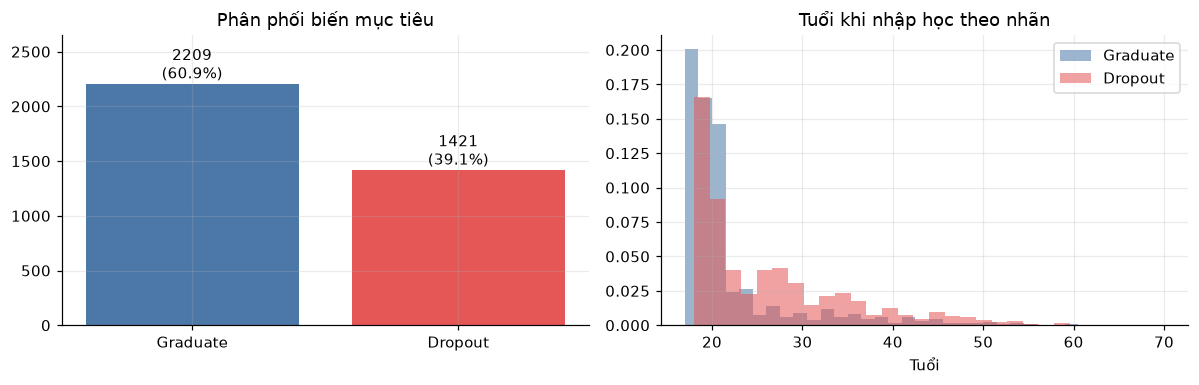

Skewness lớn nhất (|skew| > 1 là lệch mạnh):
Educational special needs                         9.37
Curricular units 1st sem (without evaluations)    8.72
Curricular units 2nd sem (without evaluations)    7.62
International                                     6.27
Curricular units 2nd sem (credited)               4.49
Marital Status                                    4.34
Curricular units 1st sem (credited)               4.06
Debtor                                            2.43


In [59]:
# (a) Phân phối biến mục tiêu
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
vc = labeled[U.TARGET].value_counts()
bars = ax[0].bar(vc.index, vc.values, color=["#4C78A8" if i == "Graduate" else "#E45756" for i in vc.index])
for b in bars:
    ax[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(b.get_height())}\n({b.get_height()/len(labeled):.1%})", ha="center", va="bottom")
ax[0].set_title("Phân phối biến mục tiêu"); ax[0].set_ylim(0, vc.max() * 1.2)

for lab, color in ((0, "#4C78A8"), (1, "#E45756")):
    ax[1].hist(labeled.loc[labeled["label"] == lab, "Age at enrollment"], bins=30, alpha=.55, color=color,
               density=True, label=["Graduate", "Dropout"][lab])
ax[1].set_title("Tuổi khi nhập học theo nhãn"); ax[1].set_xlabel("Tuổi"); ax[1].legend()
show("eda_target_age")

# Độ lệch (skewness) của biến số
num_cols = [c for c in feat_cols if c not in U.CAT_COLS]
sk = labeled[num_cols].skew().sort_values(key=abs, ascending=False)
print("Skewness lớn nhất (|skew| > 1 là lệch mạnh):")
print(sk.head(8).round(2).to_string())

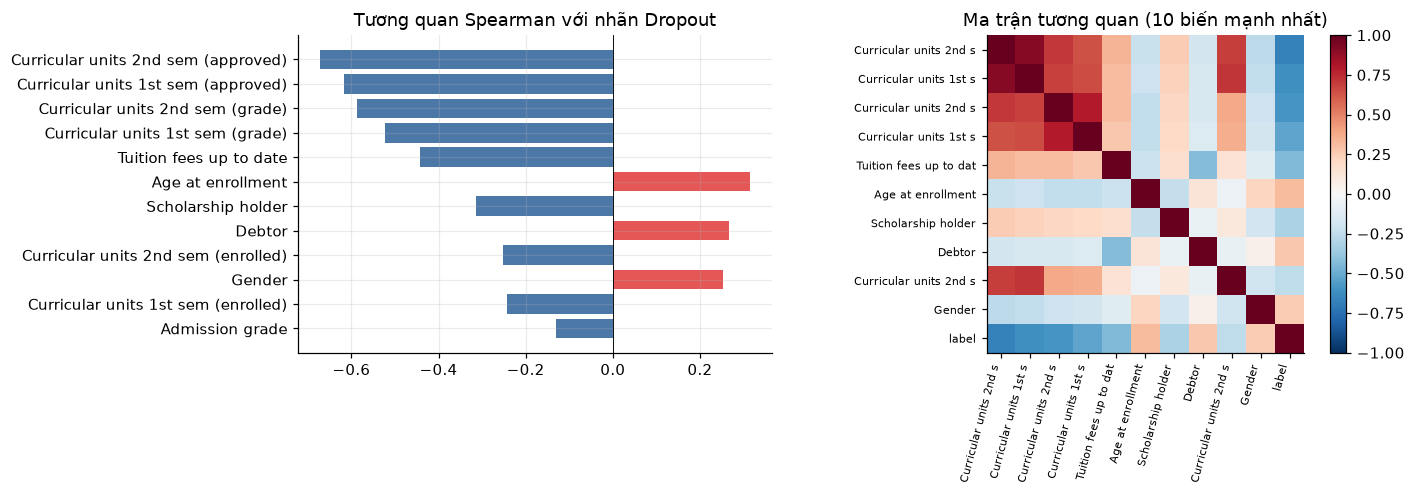

Cặp biến tương quan rất cao (|rho| > 0.8, nguy cơ đa cộng tuyến):
[('Curricular units 2nd sem (approved)', 'Curricular units 1st sem (approved)', np.float64(0.91))]


In [60]:
# (b) Tương quan với nhãn (Spearman) và ma trận tương quan các biến nổi bật
corr_y = labeled[num_cols].corrwith(labeled["label"], method="spearman").dropna()
top = corr_y.reindex(corr_y.abs().sort_values(ascending=False).index).head(12)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].barh(top.index[::-1], top.values[::-1], color=["#E45756" if v > 0 else "#4C78A8" for v in top.values[::-1]])
ax[0].set_title("Tương quan Spearman với nhãn Dropout"); ax[0].axvline(0, color="k", lw=.6)
cm = labeled[list(top.index[:10]) + ["label"]].corr(method="spearman")
im = ax[1].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(cm))); ax[1].set_xticklabels([c[:22] for c in cm.columns], rotation=75, ha="right", fontsize=7)
ax[1].set_yticks(range(len(cm))); ax[1].set_yticklabels([c[:22] for c in cm.index], fontsize=7)
ax[1].set_title("Ma trận tương quan (10 biến mạnh nhất)"); ax[1].grid(False); plt.colorbar(im, ax=ax[1], fraction=.04)
show("eda_correlation")
print("Cặp biến tương quan rất cao (|rho| > 0.8, nguy cơ đa cộng tuyến):")
pairs = [(a, b, round(cm.loc[a, b], 2)) for i, a in enumerate(cm.index[:-1]) for b in cm.columns[i + 1:-1] if abs(cm.loc[a, b]) > .8]
print(pairs if pairs else "không có")

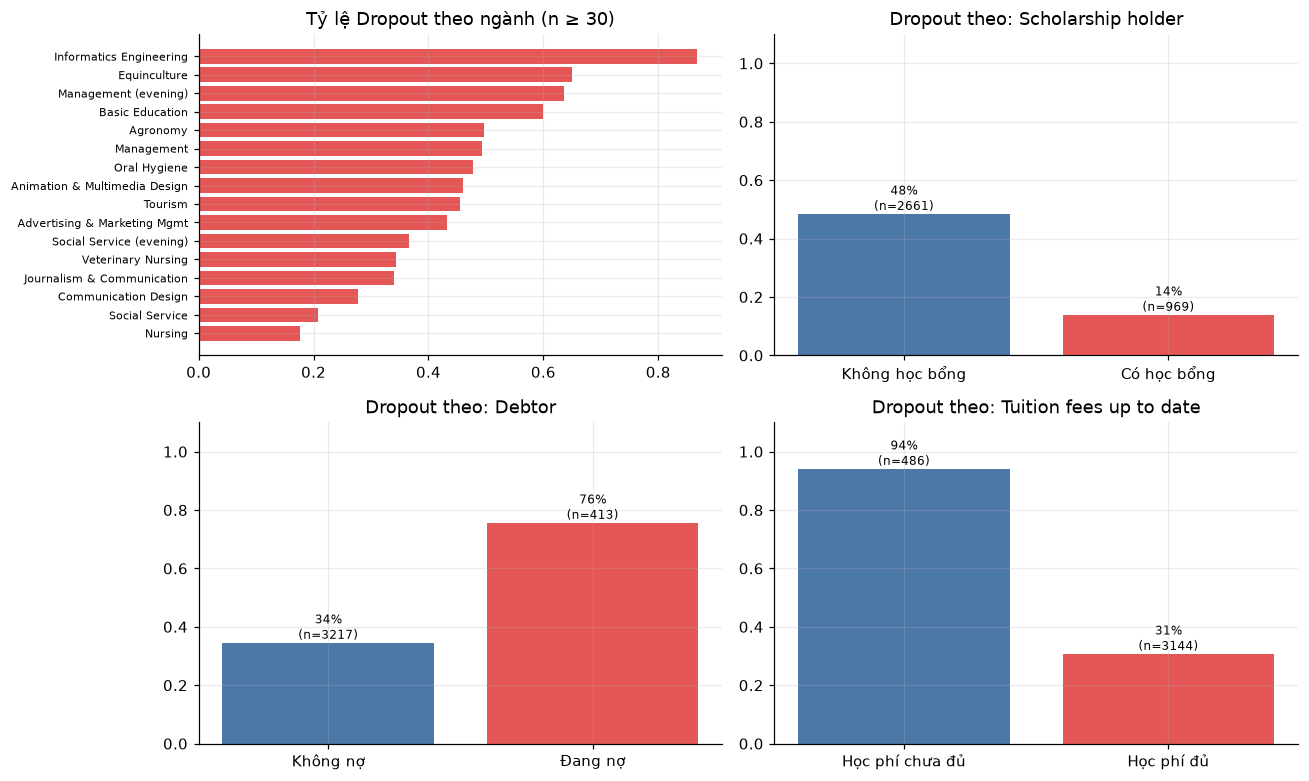

Dropout theo nhóm tuổi:
                    dropout_rate     n
Age at enrollment                    
≤19                       0.252  1621
20–24                     0.369  1033
≥25                       0.647   976

Ngành có Dropout cao nhất: [('Informatics Engineering', 0.87), ('Equinculture', 0.65), ('Management (evening)', 0.64)]
Ngành có Dropout thấp nhất: [('Communication Design', 0.28), ('Social Service', 0.21), ('Nursing', 0.18)]


In [61]:
# (c) Tỷ lệ Dropout theo các nhóm nghiệp vụ
def rate_table(series, min_n=1):
    g = labeled.groupby(series)["label"].agg(dropout_rate="mean", n="count")
    return g[g["n"] >= min_n]

fig, ax = plt.subplots(2, 2, figsize=(12, 7.2))
rt = rate_table("Course", 30).sort_values("dropout_rate")
ax[0, 0].barh([U.COURSE_NAMES.get(int(c), str(c)) for c in rt.index], rt["dropout_rate"], color="#E45756")
ax[0, 0].set_title("Tỷ lệ Dropout theo ngành (n ≥ 30)"); ax[0, 0].tick_params(axis="y", labelsize=7)
panels = [("Scholarship holder", {0: "Không học bổng", 1: "Có học bổng"}, ax[0, 1]),
          ("Debtor", {0: "Không nợ", 1: "Đang nợ"}, ax[1, 0]),
          ("Tuition fees up to date", {0: "Học phí chưa đủ", 1: "Học phí đủ"}, ax[1, 1])]
for col, mp, a in panels:
    r = rate_table(col)
    a.bar([mp.get(i, i) for i in r.index], r["dropout_rate"], color=["#4C78A8", "#E45756"][:len(r)])
    for x, (v, n) in enumerate(zip(r["dropout_rate"], r["n"])):
        a.text(x, v, f"{v:.0%}\n(n={n})", ha="center", va="bottom", fontsize=8)
    a.set_ylim(0, 1.1); a.set_title(f"Dropout theo: {col}")
show("eda_dropout_by_group")

age_bin = pd.cut(labeled["Age at enrollment"], [0, 19, 24, 200], labels=["≤19", "20–24", "≥25"])
print("Dropout theo nhóm tuổi:\n", rate_table(age_bin).round(3).to_string())
rt_big = rate_table("Course", 50).sort_values("dropout_rate", ascending=False)
print("\nNgành có Dropout cao nhất:", [(U.COURSE_NAMES.get(int(c), c), round(v, 2)) for c, v in rt_big["dropout_rate"].head(3).items()])
print("Ngành có Dropout thấp nhất:", [(U.COURSE_NAMES.get(int(c), c), round(v, 2)) for c, v in rt_big["dropout_rate"].tail(3).items()])

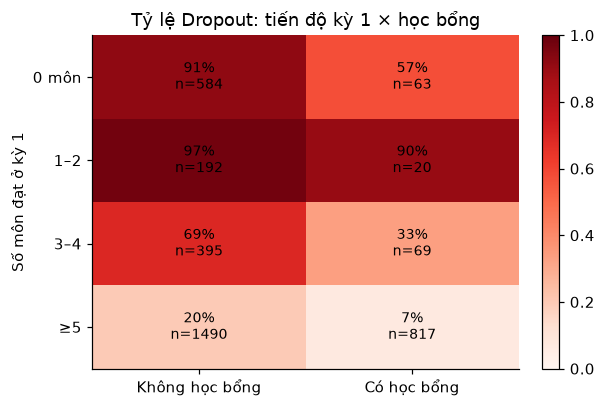

In [62]:
# (d) Phân tích đa biến: số môn đạt kỳ 1 x học bổng
a1 = pd.cut(labeled["Curricular units 1st sem (approved)"], [-1, 0, 2, 4, 100], labels=["0 môn", "1–2", "3–4", "≥5"])
pv = labeled.pivot_table(index=a1, columns="Scholarship holder", values="label", aggfunc="mean")
nn = labeled.pivot_table(index=a1, columns="Scholarship holder", values="label", aggfunc="count")
fig, ax = plt.subplots(figsize=(5.6, 3.8))
im = ax.imshow(pv.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(["Không học bổng", "Có học bổng"][:pv.shape[1]])
ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index); ax.grid(False)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax.text(j, i, f"{pv.values[i, j]:.0%}\nn={int(nn.values[i, j])}", ha="center", va="center", fontsize=9)
ax.set_ylabel("Số môn đạt ở kỳ 1"); ax.set_title("Tỷ lệ Dropout: tiến độ kỳ 1 × học bổng"); plt.colorbar(im, fraction=.05)
show("eda_multivariate")

### 3.3 Tiền xử lý & feature engineering

In [63]:
# Thiếu dữ liệu
miss = labeled[feat_cols].isna().sum()
print("Biến có giá trị thiếu:", miss[miss > 0].to_dict() or "không có")

# Ngoại lai theo quy tắc IQR (chỉ thống kê, chưa loại bỏ)
check = ["Age at enrollment", "Admission grade", "Previous qualification (grade)",
         "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)"]
rows = []
for c in check:
    q1, q3 = labeled[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((labeled[c] < q1 - 1.5 * iqr) | (labeled[c] > q3 + 1.5 * iqr)).sum())
    rows.append((c, n_out, f"{n_out/len(labeled):.1%}"))
print(pd.DataFrame(rows, columns=["Biến", "Số ngoại lai (IQR)", "Tỷ lệ"]).to_string(index=False))

Biến có giá trị thiếu: không có
                               Biến  Số ngoại lai (IQR) Tỷ lệ
                  Age at enrollment                 389 10.7%
                    Admission grade                  71  2.0%
     Previous qualification (grade)                 146  4.0%
Curricular units 1st sem (enrolled)                 366 10.1%
Curricular units 1st sem (approved)                 165  4.5%
   Curricular units 1st sem (grade)                 652 18.0%


**Quyết định xử lý:** giá trị thiếu → imputer nằm trong pipeline; ngoại lai → giữ nguyên (là giá trị thật, ví dụ sinh viên lớn tuổi), dùng `RobustScaler`; biến định danh → One-Hot, nhóm hiếm gộp lại.

In [64]:
# Feature engineering (giải thích các biến mới ở bảng bên dưới)
labeled_fe = U.add_features(labeled)
X = labeled_fe.drop(columns=[U.TARGET, "label"]); y = labeled_fe["label"]

new_feats = [c for c in X.columns if c not in feat_cols]
print("Biến mới tạo (chỉ dùng thông tin trong cùng một dòng, nên không rò rỉ giữa train/test):")
print(new_feats)
print("\nTương quan Spearman của biến mới với nhãn:")
print(X[new_feats].corrwith(y, method="spearman").round(3).sort_values(key=abs, ascending=False).to_string())

Biến mới tạo (chỉ dùng thông tin trong cùng một dòng, nên không rò rỉ giữa train/test):
['grade_gap', 's1_approval_rate', 's1_eval_pass_rate', 's1_no_eval_rate', 's1_ghost', 's2_approval_rate', 's2_eval_pass_rate', 's2_no_eval_rate', 's2_ghost', 'd_approval_rate', 'd_approved', 'd_grade', 'fin_risk', 'fin_no_aid']

Tương quan Spearman của biến mới với nhãn:
s2_approval_rate    -0.726
s2_eval_pass_rate   -0.691
s1_approval_rate    -0.673
s1_eval_pass_rate   -0.638
fin_no_aid           0.438
fin_risk             0.428
s2_ghost             0.317
s1_ghost             0.276
d_approval_rate     -0.233
d_approved          -0.231
d_grade             -0.143
s2_no_eval_rate      0.096
s1_no_eval_rate      0.087
grade_gap           -0.009


**Feature engineering từ nghiệp vụ** (định nghĩa chi tiết trong `dropout_utils.add_features`):
| Biến mới | Ý nghĩa nghiệp vụ |
|---|---|
| `grade_gap` | Điểm đầu vào trừ điểm bằng cấp trước, đo đà học so với nền tảng cũ |
| `s1_approval_rate`, `s2_approval_rate` | Số môn đạt / số môn đăng ký: tiến độ học thật sự |
| `s1_eval_pass_rate`, `s2_eval_pass_rate` | Số môn đạt / số lần thi: hiệu quả thi cử |
| `s1_no_eval_rate`, `s2_no_eval_rate` | Tỷ lệ môn không có đánh giá: tín hiệu rời bỏ sớm |
| `s1_ghost`, `s2_ghost` | Đăng ký môn nhưng không có lần đánh giá nào ("sinh viên ma") |
| `d_approval_rate`, `d_approved`, `d_grade` | Xu hướng giữa hai kỳ (chỉ dùng ở kịch bản S2) |
| `fin_risk`, `fin_no_aid` | Áp lực tài chính: nợ/chưa đủ học phí, và không có học bổng |

In [65]:
# Chia dữ liệu: Test giữ kín hoàn toàn; Train/Validation = 5-fold CV trên phần còn lại (dev)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Dev (train+validation qua 5-fold): {len(X_dev)} | Test (giữ kín): {len(X_test)}")
print(f"Tỷ lệ Dropout: dev {y_dev.mean():.3f} | test {y_test.mean():.3f}")
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

# Mất cân bằng lớp: thử class_weight, nếu AUC không đổi thì không cần resampling
cols_tmp = U.scenario_columns(PRIMARY, X.columns)
for cw in (None, "balanced"):
    pipe = U.build_pipeline("LR", cols_tmp, {"class_weight": cw})
    s = cross_validate(pipe, X_dev[cols_tmp], y_dev, cv=cv, scoring=["roc_auc", "recall"], n_jobs=1)
    print(f"LR class_weight={cw!s:9}: AUC {s['test_roc_auc'].mean():.3f} | Recall@0.5 {s['test_recall'].mean():.3f}")

Dev (train+validation qua 5-fold): 2904 | Test (giữ kín): 726
Tỷ lệ Dropout: dev 0.392 | test 0.391
LR class_weight=None     : AUC 0.919 | Recall@0.5 0.777
LR class_weight=balanced : AUC 0.919 | Recall@0.5 0.827


Mất cân bằng nhẹ nên không dùng SMOTE; ngưỡng quyết định chọn theo chi phí (§5.1). **Chống rò rỉ:** imputer, scaler, one-hot và mô hình đều nằm trong `Pipeline`; biến mới chỉ dùng thông tin cùng một dòng; tập test không dùng để chọn gì.

## 4. Thiết kế, huấn luyện & tối ưu mô hình
### 4.0 Kịch bản theo thời điểm dự báo
S0: lúc nhập học · S1: hết kỳ 1 · S1F: S1 + nợ/học phí · S2: hết kỳ 2 + tài chính (đối chứng, quá muộn).

kịch_bản mô_hình  n_biến  ROC_AUC  PR_AUC
      S0      LR      23    0.800   0.723
      S0     XGB      23    0.811   0.744
      S1      LR      33    0.919   0.908
      S1     XGB      33    0.920   0.913
     S1F      LR      37    0.932   0.927
     S1F     XGB      37    0.934   0.930
      S2      LR      50    0.945   0.942
      S2     XGB      50    0.951   0.949


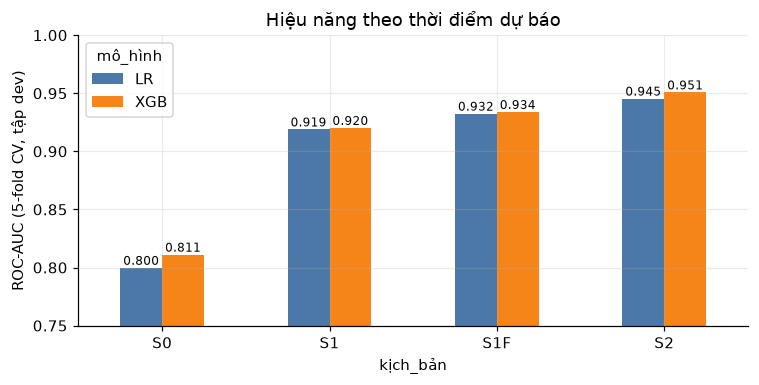

In [66]:
rows = []
for sc in ["S0", "S1", "S1F", "S2"]:
    cols_sc = U.scenario_columns(sc, X.columns)
    for m in ["LR", "XGB"]:
        s = cross_validate(U.build_pipeline(m, cols_sc), X_dev[cols_sc], y_dev, cv=cv,
                           scoring=["roc_auc", "average_precision"], n_jobs=1)
        rows.append(dict(kịch_bản=sc, mô_hình=m, n_biến=len(cols_sc),
                         ROC_AUC=s["test_roc_auc"].mean(), PR_AUC=s["test_average_precision"].mean()))
sc_tab = pd.DataFrame(rows)
print(sc_tab.round(3).to_string(index=False))

pv = sc_tab.pivot(index="kịch_bản", columns="mô_hình", values="ROC_AUC").loc[["S0", "S1", "S1F", "S2"]]
ax = pv.plot.bar(figsize=(7, 3.6), color=["#4C78A8", "#F58518"], rot=0)
ax.set_ylim(max(.5, pv.values.min() - .05), 1); ax.set_ylabel("ROC-AUC (5-fold CV, tập dev)")
ax.set_title("Hiệu năng theo thời điểm dự báo")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
show("scenario_comparison")

AUC tăng mạnh S1 → S1F → S2 phần lớn do thông tin đến muộn hoặc là hệ quả của việc nghỉ học. Kịch bản chính là **S1** (đủ sớm để can thiệp); S2 chỉ là mốc đối chứng.

In [67]:
cols = U.scenario_columns(PRIMARY, X.columns)
print(U.SCENARIO_LABELS[PRIMARY], "->", len(cols), "biến đầu vào")

def cv_scores(pipe):
    s = cross_validate(pipe, X_dev[cols], y_dev, cv=cv, scoring=["roc_auc", "average_precision"],
                       return_train_score=True, n_jobs=1)
    return dict(auc_mean=s["test_roc_auc"].mean(), auc_std=s["test_roc_auc"].std(),
                ap_mean=s["test_average_precision"].mean(), train_auc=s["train_roc_auc"].mean())

# 4.1 Baseline
base_rows = {"Dummy (tỷ lệ lớp)": cv_scores(U.build_pipeline("Dummy", cols)),
             "Logistic Regression (mặc định)": cv_scores(U.build_pipeline("LR", cols))}
single = next((c for c in ["s1_approval_rate", "Curricular units 1st sem (approved)", "Admission grade"] if c in cols), None)
if single:  # baseline đơn biến, chiều ảnh hưởng cố định theo logic nghiệp vụ (điểm/tiến độ cao -> rủi ro thấp)
    a = roc_auc_score(y_dev, -X_dev[single])
    base_rows[f"Luật đơn biến: {single}"] = dict(auc_mean=a, auc_std=np.nan, ap_mean=average_precision_score(y_dev, -X_dev[single]), train_auc=np.nan)
baseline_tab = pd.DataFrame(base_rows).T
print("\n4.1 BASELINE (5-fold CV trên dev)")
print(baseline_tab.round(3).to_string())

S1 - Hết học kỳ 1 (không gồm tài chính) -> 33 biến đầu vào

4.1 BASELINE (5-fold CV trên dev)
                                 auc_mean  auc_std  ap_mean  train_auc
Dummy (tỷ lệ lớp)                   0.500    0.000    0.392      0.500
Logistic Regression (mặc định)      0.919    0.008    0.908      0.938
Luật đơn biến: s1_approval_rate     0.880      NaN    0.816        NaN


In [68]:
# 4.2 Ba mô hình nâng cao (tham số mặc định) với 5-fold Cross-Validation
default_tab = pd.DataFrame({m: cv_scores(U.build_pipeline(m, cols)) for m in ["LR", "RF", "XGB"]}).T
print("4.2 MÔ HÌNH NÂNG CAO, tham số mặc định (5-fold CV trên dev)")
print(default_tab.round(3).to_string())

4.2 MÔ HÌNH NÂNG CAO, tham số mặc định (5-fold CV trên dev)
     auc_mean  auc_std  ap_mean  train_auc
LR      0.919    0.008    0.908      0.938
RF      0.920    0.008    0.913      0.997
XGB     0.920    0.008    0.913      0.990


### 4.3 Tinh chỉnh siêu tham số và cân nhắc tài nguyên

Optuna tối ưu ROC-AUC bằng 5-fold CV. Sau đó benchmark thời gian huấn luyện, độ trễ dự đoán và kích thước mô hình trên cùng máy. Nhóm chấp nhận mô hình có AUC thấp hơn tối đa 0,01 so với mô hình tốt nhất, rồi ưu tiên mô hình dự đoán nhanh hơn; tiêu chí phụ là file nhỏ hơn và thời gian fit ngắn hơn. Ngưỡng 0,01 là quyết định nghiệp vụ cần nêu rõ, không phải quy luật phổ quát.


LR   best CV AUC 0.9190 | {'C': 0.9816694931502011}
RF   best CV AUC 0.9207 | {'n_estimators': 100, 'max_depth': 11, 'min_samples_leaf': 1, 'max_features': 0.3}
XGB  best CV AUC 0.9244 | {'n_estimators': 350, 'learning_rate': 0.029730317172472848, 'max_depth': 3, 'subsample': 0.9322073493310126, 'colsample_bytree': 0.7678053786012357, 'min_child_weight': 2, 'reg_lambda': 0.20735021691594704}
Thời gian tuning: 109s


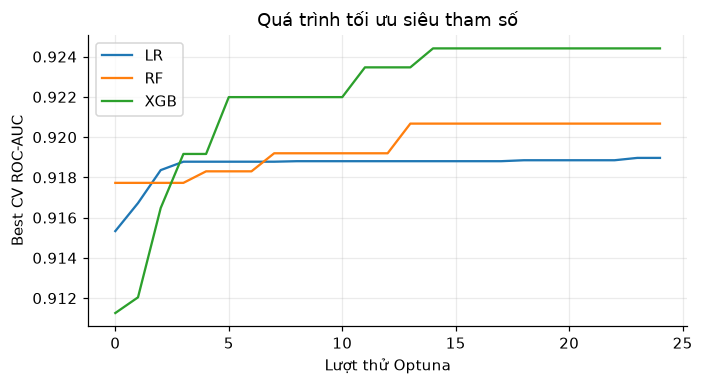

In [69]:
def space(model, t):
    if model == "LR":
        return dict(C=t.suggest_float("C", 1e-3, 30, log=True))
    if model == "RF":
        return dict(n_estimators=t.suggest_int("n_estimators", 100, 400, step=50),
                    max_depth=t.suggest_int("max_depth", 3, 20),
                    min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 12),
                    max_features=t.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]))
    if model == "XGB":
        return dict(n_estimators=t.suggest_int("n_estimators", 100, 500, step=50),
                    learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                    max_depth=t.suggest_int("max_depth", 2, 6),
                    subsample=t.suggest_float("subsample", 0.6, 1.0),
                    colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
                    min_child_weight=t.suggest_int("min_child_weight", 1, 10),
                    reg_lambda=t.suggest_float("reg_lambda", 1e-2, 10, log=True))

best_params, studies = {}, {}
t0 = time.time()
for m in ["LR", "RF", "XGB"]:
    def objective(trial, m=m):
        pipe = U.build_pipeline(m, cols, space(m, trial))
        return cross_val_score(pipe, X_dev[cols], y_dev, cv=cv, scoring="roc_auc", n_jobs=1).mean()
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(objective, n_trials=N_TRIALS)
    studies[m], best_params[m] = st, st.best_params
    print(f"{m:4} best CV AUC {st.best_value:.4f} | {st.best_params}")
print(f"Thời gian tuning: {time.time()-t0:.0f}s")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for m, st in studies.items():
    v = [t.value for t in st.trials]; ax.plot(np.maximum.accumulate(v), label=m)
ax.set_xlabel("Lượt thử Optuna"); ax.set_ylabel("Best CV ROC-AUC"); ax.legend(); ax.set_title("Quá trình tối ưu siêu tham số")
show("optuna_history")

In [70]:
import io
# So sánh CV ROC-AUC trước/sau tinh chỉnh (trên dev)
tuned_tab = pd.DataFrame({m: cv_scores(U.build_pipeline(m, cols, best_params[m])) for m in ["LR", "RF", "XGB"]}).T
cmp_tab = pd.concat({"Mặc định": default_tab[["auc_mean", "auc_std"]], "Đã tinh chỉnh": tuned_tab[["auc_mean", "auc_std"]]}, axis=1)
print(cmp_tab.round(4).to_string())
print("\nAUC CV dùng để chọn mô hình/tham số; đánh giá cuối cùng vẫn dùng tập test ở §5.")

# Đo tài nguyên trên cùng dữ liệu dev và cùng kích thước mẫu.
# Tolerance AUC là mức suy giảm tối đa chấp nhận được để đổi lấy mô hình nhẹ hơn.
AUC_TOL = 0.01
BENCH_REPEATS = 3
BENCH_N = min(300, len(X_dev))
X_bench = X_dev[cols].sample(BENCH_N, random_state=SEED)
resource_rows = []
for m in ["LR", "RF", "XGB"]:
    fit_times, predict_times, model_sizes = [], [], []
    for _ in range(BENCH_REPEATS):
        candidate = U.build_pipeline(m, cols, best_params[m])
        t0 = time.perf_counter()
        candidate.fit(X_dev[cols], y_dev)
        fit_times.append(time.perf_counter() - t0)

        # Đo độ trễ dự đoán trên cùng một batch; lặp để giảm nhiễu đồng hồ.
        t0 = time.perf_counter()
        for _ in range(20):
            candidate.predict_proba(X_bench)
        predict_times.append((time.perf_counter() - t0) / (20 * BENCH_N) * 1000)  # ms / hồ sơ

        buffer = io.BytesIO()
        joblib.dump(candidate, buffer)
        model_sizes.append(buffer.tell() / (1024 ** 2))  # MiB

    resource_rows.append({
        "mô_hình": m,
        "ROC_AUC_CV": tuned_tab.loc[m, "auc_mean"],
        "thời_gian_fit_giây": np.median(fit_times),
        "độ_trễ_dự_đoán_ms_mỗi_hồ_sơ": np.median(predict_times),
        "kích_thước_MiB": np.median(model_sizes),
    })
resource_tab = pd.DataFrame(resource_rows).set_index("mô_hình")


    Mặc định         Đã tinh chỉnh        
    auc_mean auc_std      auc_mean auc_std
LR    0.9189  0.0080        0.9190  0.0079
RF    0.9203  0.0082        0.9207  0.0134
XGB   0.9201  0.0081        0.9244  0.0053

AUC CV dùng để chọn mô hình/tham số; đánh giá cuối cùng vẫn dùng tập test ở §5.


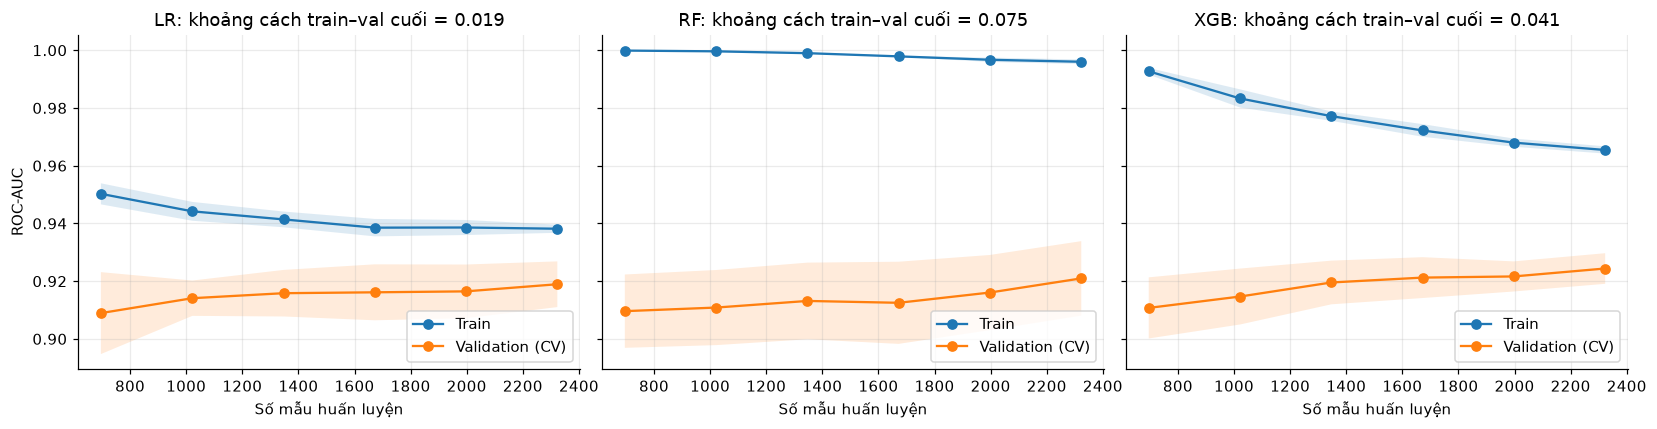

     AUC train  AUC validation (CV)  Khoảng cách
LR       0.938                0.919        0.019
RF       0.996                0.921        0.075
XGB      0.965                0.924        0.041


In [71]:
# Learning curve: kiểm tra overfitting / underfitting
sizes = np.linspace(0.3, 1.0, 4 if FAST else 6)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, m in zip(axes.ravel(), ["LR", "RF", "XGB"]):
    ns, tr, va = learning_curve(U.build_pipeline(m, cols, best_params[m]), X_dev[cols], y_dev, cv=cv,
                                train_sizes=sizes, scoring="roc_auc", n_jobs=1, random_state=SEED)
    ax.plot(ns, tr.mean(1), "o-", label="Train"); ax.fill_between(ns, tr.mean(1)-tr.std(1), tr.mean(1)+tr.std(1), alpha=.15)
    ax.plot(ns, va.mean(1), "o-", label="Validation (CV)"); ax.fill_between(ns, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.15)
    ax.set_title(f"{m}: khoảng cách train–val cuối = {tr.mean(1)[-1]-va.mean(1)[-1]:.3f}"); ax.set_xlabel("Số mẫu huấn luyện")
    if m == "LR": ax.set_ylabel("ROC-AUC")
    ax.legend(loc="lower right")
show("learning_curves")

gap = tuned_tab[["train_auc", "auc_mean"]].rename(columns={"train_auc": "AUC train", "auc_mean": "AUC validation (CV)"})
gap["Khoảng cách"] = gap["AUC train"] - gap["AUC validation (CV)"]
print(gap.round(3).to_string())

**Cách đọc:** hai đường gần nhau nhưng thấp → underfitting; train cao, validation thấp hơn nhiều → overfitting.

### Chốt mô hình sau khi xem xét overfitting và tài nguyên

Đọc learning curves và khoảng cách train–validation ở trên trước khi chốt. Sau đó, trong nhóm mô hình có ROC-AUC CV cách mức cao nhất không quá `AUC_TOL`, ưu tiên độ trễ dự đoán thấp; nếu gần nhau thì xét kích thước mô hình và thời gian fit. Overfitting được dùng để xem xét/diễn giải trước khi quyết định; tập test vẫn để dành cho đánh giá cuối ở Phần 5.


In [72]:
# Giữ các mô hình có AUC nằm trong AUC_TOL so với mô hình tốt nhất,
# sau đó ưu tiên dự đoán nhanh; nếu gần nhau thì chọn file nhỏ hơn rồi fit nhanh hơn.
best_auc = resource_tab["ROC_AUC_CV"].max()
eligible = resource_tab[resource_tab["ROC_AUC_CV"] >= best_auc - AUC_TOL].copy()
ranked = eligible.sort_values(
    ["độ_trễ_dự_đoán_ms_mỗi_hồ_sơ", "kích_thước_MiB", "thời_gian_fit_giây"],
    ascending=True,
)
FINAL = ranked.index[0]

print(f"\nNgưỡng đánh đổi: chấp nhận AUC thấp hơn tối đa {AUC_TOL:.3f} so với mức tốt nhất ({best_auc:.4f}).")
print("Bảng đo tài nguyên (benchmark trên máy chạy notebook; thời gian có thể thay đổi theo máy):")
print(resource_tab.round(4).to_string())
print("\nCác mô hình đủ gần AUC tốt nhất:", list(eligible.index))
print("=> Chọn theo độ trễ dự đoán thấp nhất; hòa thì ưu tiên file nhỏ hơn, sau đó fit nhanh hơn:", FINAL)



Ngưỡng đánh đổi: chấp nhận AUC thấp hơn tối đa 0.010 so với mức tốt nhất (0.9244).
Bảng đo tài nguyên (benchmark trên máy chạy notebook; thời gian có thể thay đổi theo máy):
         ROC_AUC_CV  thời_gian_fit_giây  độ_trễ_dự_đoán_ms_mỗi_hồ_sơ  kích_thước_MiB
mô_hình                                                                             
LR           0.9190              0.0411                       0.0131          0.0121
RF           0.9207              0.2328                       0.2475          2.6088
XGB          0.9244              0.3048                       0.0174          0.3926

Các mô hình đủ gần AUC tốt nhất: ['LR', 'RF', 'XGB']
=> Chọn theo độ trễ dự đoán thấp nhất; hòa thì ưu tiên file nhỏ hơn, sau đó fit nhanh hơn: LR


## 5. Đánh giá chuyên sâu, giải thích mô hình & đạo đức AI
### 5.1 Chỉ số kỹ thuật, ngưỡng theo chi phí và ma trận nhầm lẫn

In [73]:
grid = np.round(np.linspace(0.05, 0.95, 91), 2)
pipes = {m: U.build_pipeline(m, cols, best_params[m]) for m in ["LR", "RF", "XGB"]}
pipes["LR_base"] = U.build_pipeline("LR", cols)                 # baseline mặc định để đối chiếu
fitted, oof, test_p = {}, {}, {}
for m, pipe in pipes.items():
    # oof = dự báo "ngoài fold" trên tập dev -> đóng vai trò VALIDATION để chọn ngưỡng (không đụng tập test)
    oof[m] = cross_val_predict(clone(pipe), X_dev[cols], y_dev, cv=cv, method="predict_proba")[:, 1]
    fitted[m] = clone(pipe).fit(X_dev[cols], y_dev)
    test_p[m] = fitted[m].predict_proba(X_test[cols])[:, 1]

def best_t(m, c=C_INT, s=S_SUCCESS):
    nb = U.net_benefit_table(y_dev, oof[m], grid, L_LOSS, c, s)
    return float(nb.loc[nb["net"].idxmax(), "threshold"])

rows = []
for m in ["LR_base", "LR", "RF", "XGB"]:
    t = best_t(m); r = U.metrics_at(y_test, test_p[m], t)
    nb = U.net_benefit_table(y_test, test_p[m], [t], L_LOSS, C_INT, S_SUCCESS).iloc[0]
    rows.append(dict(mô_hình=m, ROC_AUC=roc_auc_score(y_test, test_p[m]), PR_AUC=average_precision_score(y_test, test_p[m]),
                     ngưỡng=t, accuracy=r["accuracy"], precision=r["precision"], recall=r["recall"], f1=r["f1"],
                     tỷ_lệ_gắn_cờ=r["flagged"] / len(y_test), lợi_ích_ròng_trên_SV=nb["net_per_student"]))
test_tab = pd.DataFrame(rows).set_index("mô_hình")
print(f"KẾT QUẢ TRÊN TẬP TEST (kịch bản {PRIMARY}; ngưỡng chọn bằng lợi ích ròng trên OOF của dev)")
print(test_tab.round(3).to_string())
print(f"\nMô hình chọn: {FINAL}")

KẾT QUẢ TRÊN TẬP TEST (kịch bản S1; ngưỡng chọn bằng lợi ích ròng trên OOF của dev)
         ROC_AUC  PR_AUC  ngưỡng  accuracy  precision  recall     f1  tỷ_lệ_gắn_cờ  lợi_ích_ròng_trên_SV
mô_hình                                                                                                 
LR_base    0.931   0.916    0.19     0.791      0.664   0.940  0.778         0.554                 0.083
LR         0.931   0.916    0.19     0.791      0.664   0.940  0.778         0.554                 0.083
RF         0.936   0.924    0.22     0.826      0.718   0.915  0.805         0.499                 0.083
XGB        0.939   0.929    0.20     0.820      0.703   0.933  0.802         0.519                 0.084

Mô hình chọn: LR


**Vì sao Recall/PR-AUC thay Accuracy?** Bỏ sót một sinh viên (FN) tốn khoảng L, gắn cờ nhầm (FP) chỉ tốn C nhỏ hơn nhiều; Accuracy coi hai loại sai như nhau nên không phản ánh bài toán. L, C, S là giả định ở cell cấu hình, cần thay bằng số có nguồn.

Ngưỡng theo lợi ích ròng t* = 0.19 (mặc định 0.50)


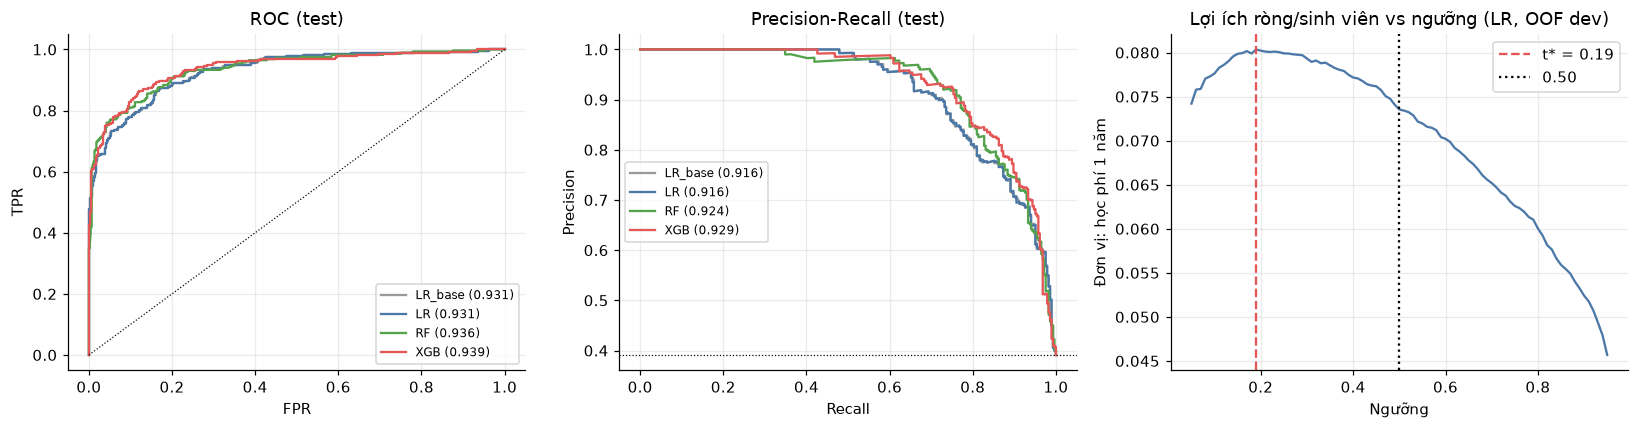

In [74]:
t_net = best_t(FINAL)
nb_oof = U.net_benefit_table(y_dev, oof[FINAL], grid, L_LOSS, C_INT, S_SUCCESS)
print(f"Ngưỡng theo lợi ích ròng t* = {t_net:.2f} (mặc định 0.50)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for m, c in zip(["LR_base", "LR", "RF", "XGB"], ["#999", "#4C78A8", "#54A24B", "#E45756"]):
    fpr, tpr, _ = roc_curve(y_test, test_p[m]); ax[0].plot(fpr, tpr, color=c, label=f"{m} ({roc_auc_score(y_test, test_p[m]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, test_p[m]); ax[1].plot(rc, pr, color=c, label=f"{m} ({average_precision_score(y_test, test_p[m]):.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=.8); ax[0].set_title("ROC (test)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend(fontsize=8)
ax[1].axhline(y_test.mean(), color="k", ls=":", lw=.8); ax[1].set_title("Precision-Recall (test)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend(fontsize=8)
ax[2].plot(nb_oof["threshold"], nb_oof["net_per_student"], color="#4C78A8")
ax[2].axvline(t_net, color="#E45756", ls="--", label=f"t* = {t_net:.2f}"); ax[2].axvline(.5, color="k", ls=":", label="0.50")
ax[2].set_title(f"Lợi ích ròng/sinh viên vs ngưỡng ({FINAL}, OOF dev)"); ax[2].set_xlabel("Ngưỡng"); ax[2].set_ylabel("Đơn vị: học phí 1 năm"); ax[2].legend()
show("roc_pr_netbenefit")

In [75]:
# Chỉ số của mô hình chọn trên tập test (tại ngưỡng t*)
yt, pt = y_test.values, test_p[FINAL]
print(f"{FINAL}, kịch bản {PRIMARY}, ngưỡng {t_net:.2f}")
print(test_tab.loc[[FINAL]].round(3).to_string())

LR, kịch bản S1, ngưỡng 0.19
         ROC_AUC  PR_AUC  ngưỡng  accuracy  precision  recall     f1  tỷ_lệ_gắn_cờ  lợi_ích_ròng_trên_SV
mô_hình                                                                                                 
LR         0.931   0.916    0.19     0.791      0.664    0.94  0.778         0.554                 0.083


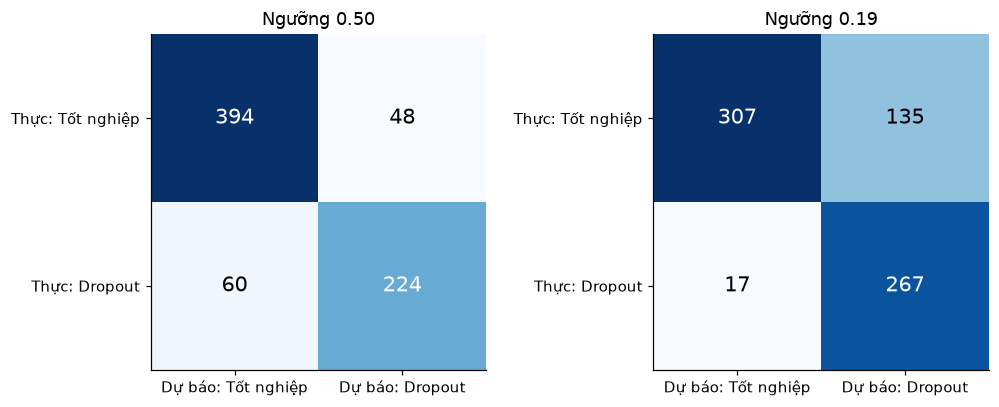

Tổn thất = L·(số Dropout − S·TP) + C·(TP+FP)  (đơn vị: học phí 1 năm, tập test)
                  gắn_cờ   TP   FP   FN  tổng_tổn_thất  tổn_thất_trên_SV  giảm_so_với_không_can_thiệp
chiến_lược                                                                                           
Không can thiệp        0    0    0  284          284.0             0.391                        0.000
Mặc định 0.50        272  224   48   60          230.4             0.317                        0.189
Chi phí t*=0.19      402  267  135   17          224.0             0.309                        0.211
Can thiệp tất cả     726  284  442    0          235.1             0.324                        0.172

KPI cho báo cáo (ngưỡng 0.19): Recall 94.0% · Precision 66.4% · gắn cờ 55.4% sinh viên · lợi ích ròng 0.083/SV · ROI 3.0x trên chi phí can thiệp


In [76]:
# Ma trận nhầm lẫn dưới góc nhìn chi phí
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
for a, t in zip(ax, [0.5, t_net]):
    cmx = confusion_matrix(y_test, (pt >= t).astype(int), labels=[0, 1])
    a.imshow(cmx, cmap="Blues"); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cmx[i, j]}", ha="center", va="center", fontsize=14, color="white" if cmx[i, j] > cmx.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["Dự báo: Tốt nghiệp", "Dự báo: Dropout"]); a.set_yticks([0, 1]); a.set_yticklabels(["Thực: Tốt nghiệp", "Thực: Dropout"])
    a.set_title(f"Ngưỡng {t:.2f}")
show("confusion_matrices")

P = int(y_test.sum())
rows = []
for name, t in (("Không can thiệp", 1.01), ("Mặc định 0.50", 0.5), (f"Chi phí t*={t_net:.2f}", t_net), ("Can thiệp tất cả", 0.0)):
    r = U.metrics_at(y_test, pt, t)
    loss = L_LOSS * (P - S_SUCCESS * r["TP"]) + C_INT * (r["TP"] + r["FP"])
    rows.append(dict(chiến_lược=name, gắn_cờ=r["flagged"], TP=r["TP"], FP=r["FP"], FN=r["FN"],
                     tổng_tổn_thất=loss, tổn_thất_trên_SV=loss / len(y_test)))
loss_tab = pd.DataFrame(rows).set_index("chiến_lược")
loss_tab["giảm_so_với_không_can_thiệp"] = 1 - loss_tab["tổng_tổn_thất"] / loss_tab.loc["Không can thiệp", "tổng_tổn_thất"]
print("Tổn thất = L·(số Dropout − S·TP) + C·(TP+FP)  (đơn vị: học phí 1 năm, tập test)")
print(loss_tab.round(3).to_string())
r = U.metrics_at(y_test, pt, t_net); nbr = U.net_benefit_table(y_test, pt, [t_net], L_LOSS, C_INT, S_SUCCESS).iloc[0]
print(f"\nKPI cho báo cáo (ngưỡng {t_net:.2f}): Recall {r['recall']:.1%} · Precision {r['precision']:.1%} · gắn cờ {r['flagged']/len(yt):.1%} sinh viên · "
      f"lợi ích ròng {nbr['net_per_student']:.3f}/SV · ROI {nbr['roi']:.1f}x trên chi phí can thiệp")

In [77]:
# Nguồn lực tư vấn có hạn: chỉ liên hệ được top-K% sinh viên theo xác suất (so với chọn ngẫu nhiên: lift = 1)
order_ = np.argsort(-pt); base_rate = yt.mean(); rows = []
for k in (0.10, 0.20, 0.30, 0.50):
    n_k = int(round(k * len(yt))); tp_k = int(yt[order_[:n_k]].sum())
    rows.append(dict(nhóm=f"Top {k:.0%}", số_SV=n_k, precision_at_K=tp_k / n_k, recall_at_K=tp_k / yt.sum(),
                     lift=(tp_k / n_k) / base_rate, lợi_ích_ròng_trên_SV=(S_SUCCESS * L_LOSS * tp_k - C_INT * n_k) / len(yt)))
cap_tab = pd.DataFrame(rows).set_index("nhóm")
print(f"Tỷ lệ Dropout nền (test): {base_rate:.1%}")
print(cap_tab.round(3).to_string())
flag_share = U.metrics_at(y_test, pt, t_net)["flagged"] / len(yt)
if flag_share > 0.6:
    print(f"\nLƯU Ý: với giả định chi phí hiện tại, ngưỡng tối ưu gắn cờ {flag_share:.0%} sinh viên, gần với 'can thiệp tất cả'. "
          "Nghĩa là khi can thiệp rẻ so với thiệt hại, mô hình ít tạo thêm giá trị so với can thiệp đại trà; "
          "giá trị của mô hình nằm ở tình huống nguồn lực giới hạn (bảng Top-K ở trên) hoặc can thiệp tốn kém.")

Tỷ lệ Dropout nền (test): 39.1%
         số_SV  precision_at_K  recall_at_K   lift  lợi_ích_ròng_trên_SV
nhóm                                                                    
Top 10%     73           1.000        0.257  2.556                 0.025
Top 20%    145           0.993        0.507  2.539                 0.050
Top 30%    218           0.913        0.701  2.334                 0.067
Top 50%    363           0.705        0.901  1.803                 0.081


### 5.2 Giải thích mô hình (XAI)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


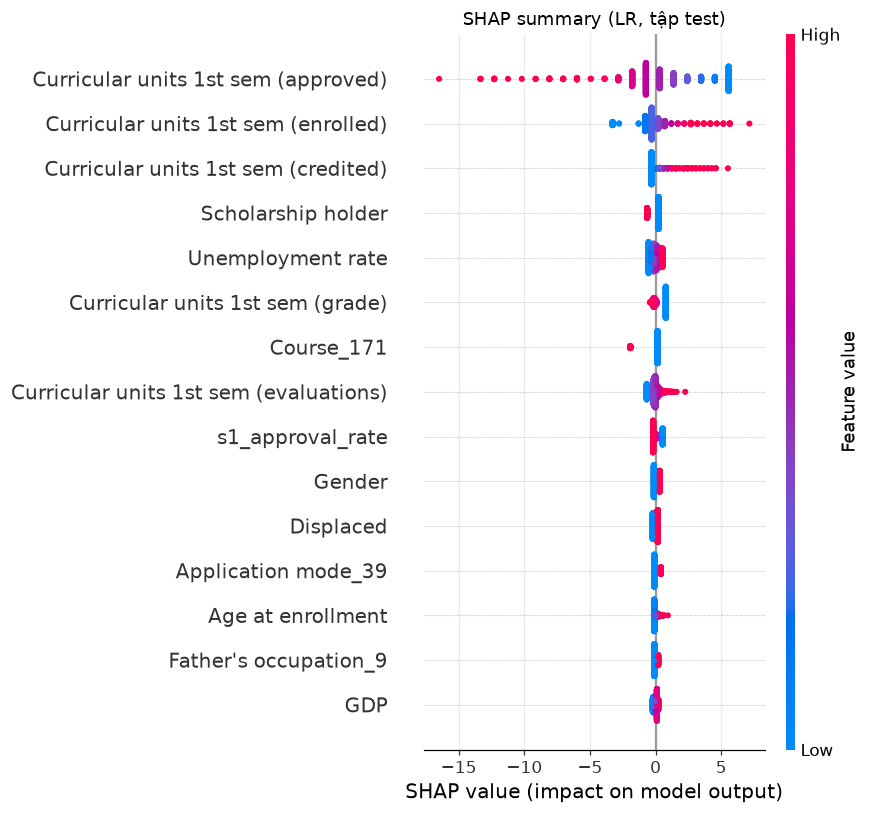

In [78]:
sv = U.shap_values(fitted[FINAL], X_test[cols], X_dev[cols])
plt.figure(figsize=(8, 5.5))
shap.summary_plot(sv["values_t"], sv["data_t"], feature_names=sv["names_t"], max_display=15, show=False)
plt.title(f"SHAP summary ({FINAL}, tập test)"); show("shap_summary")

Biến ở trên cùng ảnh hưởng nhiều nhất; chấm đỏ = giá trị biến cao, xanh = thấp; bên phải số 0 = đẩy xác suất nghỉ học lên. SHAP cho biết mô hình *dùng* biến nào, không chứng minh biến đó *gây ra* việc nghỉ học.

### 5.3 Đạo đức AI, thiên lệch thuật toán & quyền riêng tư

In [79]:
# Fairness: so sánh hiệu năng theo nhóm trên tập test tại ngưỡng đã chọn
Xt_ = X_test.copy(); pred_t = (pt >= t_net).astype(int); yv = y_test.values
groups = {
    "Giới tính": Xt_["Gender"].map({0: "Nữ", 1: "Nam"}),
    "Nhóm tuổi": pd.cut(Xt_["Age at enrollment"], [0, 19, 24, 200], labels=["≤19", "20–24", "≥25"]).astype(str),
    "Học bổng": Xt_["Scholarship holder"].map({0: "Không", 1: "Có"}),
    "Sinh viên quốc tế": Xt_["International"].map({0: "Không", 1: "Có"}),
    "Displaced (xa quê)": Xt_["Displaced"].map({0: "Không", 1: "Có"}),
    "Nhu cầu GD đặc biệt": Xt_["Educational special needs"].map({0: "Không", 1: "Có"}),
    "Hôn nhân": pd.Series(np.where(Xt_["Marital Status"] == 1, "Độc thân", "Khác"), index=Xt_.index),
}
def group_metrics(pred, y_arr, mask):
    yy, pp = y_arr[mask], pred[mask]; pos, neg = int((yy == 1).sum()), int((yy == 0).sum())
    return dict(n=int(mask.sum()), n_dropout=pos, tỷ_lệ_dropout=yy.mean() if len(yy) else np.nan, tỷ_lệ_gắn_cờ=pp.mean() if len(yy) else np.nan,
                TPR_recall=((pp == 1) & (yy == 1)).sum() / pos if pos else np.nan,
                FPR=((pp == 1) & (yy == 0)).sum() / neg if neg else np.nan,
                precision=((pp == 1) & (yy == 1)).sum() / max(pp.sum(), 1), tin_cậy="đủ" if pos >= 20 and neg >= 20 else "(*) mẫu nhỏ")
rows = []
for g, ser in groups.items():
    for lv in ser.dropna().unique():
        rows.append(dict(nhóm_thuộc_tính=g, giá_trị=lv, **group_metrics(pred_t, yv, (ser == lv).values)))
fair = pd.DataFrame(rows)
print(fair.round(3).to_string(index=False))

gaps = (fair[fair["tin_cậy"] == "đủ"].groupby("nhóm_thuộc_tính")[["tỷ_lệ_gắn_cờ", "TPR_recall", "FPR"]].agg(lambda s: s.max() - s.min()))
gaps.columns = ["Chênh lệch tỷ lệ gắn cờ (demographic parity)", "Chênh lệch Recall (equal opportunity)", "Chênh lệch FPR"]
print("\nChênh lệch giữa các nhóm (chỉ nhóm đủ cỡ mẫu):"); print(gaps.round(3).to_string())

    nhóm_thuộc_tính  giá_trị   n  n_dropout  tỷ_lệ_dropout  tỷ_lệ_gắn_cờ  TPR_recall   FPR  precision     tin_cậy
          Giới tính       Nữ 438        130          0.297         0.441       0.923 0.237      0.622          đủ
          Giới tính      Nam 288        154          0.535         0.726       0.955 0.463      0.703          đủ
          Nhóm tuổi      ≤19 318         79          0.248         0.396       0.848 0.247      0.532          đủ
          Nhóm tuổi      ≥25 187        125          0.668         0.802       0.984 0.435      0.820          đủ
          Nhóm tuổi    20–24 221         80          0.362         0.570       0.962 0.348      0.611          đủ
           Học bổng       Có 174         26          0.149         0.247       0.885 0.135      0.535          đủ
           Học bổng    Không 552        258          0.467         0.650       0.946 0.391      0.680          đủ
  Sinh viên quốc tế    Không 708        276          0.390         0.552       0.938 0.3

**Quyền riêng tư:** dùng mã sinh viên, giới hạn truy cập danh sách rủi ro. **Thiên lệch:** đọc bảng trên kèm cột `tin_cậy` (nhóm nhỏ thì không đáng tin). **Human-in-the-loop:** mô hình chỉ xếp hạng để ưu tiên liên hệ, không ra quyết định; ca mức Vàng do cố vấn xem lại.

## 6. Sản phẩm mẫu, khả năng ứng dụng & hướng phát triển
### 6.1 Danh sách can thiệp và đóng gói ứng dụng

In [80]:
# Huấn luyện lại mô hình chọn trên TOÀN BỘ dữ liệu có nhãn (dev + test) để triển khai.
# Kết quả đánh giá ở §5 vẫn là của mô hình huấn luyện trên dev; việc refit chỉ để dùng thực tế.
final_full = clone(pipes[FINAL]).fit(X[cols], y)

# Chia mức rủi ro: Vàng từ ngưỡng lợi ích ròng; Đỏ từ ngưỡng đạt precision >= 0.90 trên OOF (nếu có)
prec_oof = [U.metrics_at(y_dev, oof[FINAL], t)["precision"] for t in grid]
cand = [t for t, p_ in zip(grid, prec_oof) if p_ >= 0.90 and t > t_net]
t_low = t_net; t_high = float(cand[0]) if cand else float(min(0.95, t_net + 0.25))
print(f"Mức Vàng (cần cố vấn xem lại): p ≥ {t_low:.2f} | Mức Đỏ (ưu tiên liên hệ ngay): p ≥ {t_high:.2f}")

dep_fe = U.add_features(deploy)
X_dep = dep_fe[cols].copy()
p_dep = final_full.predict_proba(X_dep)[:, 1]
tier = np.where(p_dep >= t_high, "Đỏ", np.where(p_dep >= t_low, "Vàng", "Xanh"))
sv_dep = U.shap_values(final_full, X_dep, X[cols])
out = pd.DataFrame({"index_goc": deploy.index, "xac_suat_nghi_hoc": p_dep.round(3), "muc_rui_ro": tier,
                    "ly_do_chinh": U.top_reasons(sv_dep, 3)}).sort_values("xac_suat_nghi_hoc", ascending=False)
out.insert(0, "xep_hang", range(1, len(out) + 1))
out.to_csv("outputs/Danh_Sach_Can_Thiep.csv", index=False, encoding="utf-8-sig")
print(out["muc_rui_ro"].value_counts().to_string())
out.head(10)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


Mức Vàng (cần cố vấn xem lại): p ≥ 0.19 | Mức Đỏ (ưu tiên liên hệ ngay): p ≥ 0.62
muc_rui_ro
Vàng    310
Đỏ      283
Xanh    201


,xep_hang,index_goc,xac_suat_nghi_hoc,muc_rui_ro,ly_do_chinh
332,1,1861,1.000,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
410,2,2326,0.999,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
307,3,1753,0.999,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
156,4,854,0.999,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
415,5,2363,0.999,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
553,6,3077,0.999,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
513,7,2819,0.999,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
597,8,3335,0.999,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
688,9,3824,0.998,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...
646,10,3573,0.998,Đỏ,Curricular units 1st sem (approved) (tăng rủi ro); Curricular unit...


**Lưu ý khi đọc danh sách này:** nhóm `Enrolled` là sinh viên chưa có kết quả cuối, và mô hình chỉ học từ nhóm Graduate/Dropout (loại bỏ sinh viên còn đang học là một dạng *censoring*). Danh sách là **gợi ý ưu tiên**, chưa được kiểm chứng bằng kết quả thực tế. Cách kiểm chứng đúng là theo dõi nhóm này đến khi có kết quả cuối.

In [81]:
# Đóng gói cho app Streamlit
joblib.dump(final_full, "models/artifacts/model.joblib")
X[cols].sample(min(300, len(X)), random_state=SEED).to_csv("models/artifacts/background.csv", index=False)

raw_inputs = [c for c in feat_cols]                              # app nhận 36 cột gốc rồi tự tạo biến mới
meta = dict(
    scenario=PRIMARY, scenario_label=U.SCENARIO_LABELS[PRIMARY], model=FINAL, columns=cols, raw_inputs=raw_inputs,
    t_low=t_low, t_high=t_high, cost=dict(L=L_LOSS, c=C_INT, s=S_SUCCESS),
    defaults={c: float(labeled[c].median()) for c in raw_inputs},
    choices={c: sorted(int(v) for v in labeled[c].dropna().unique()) for c in U.CAT_COLS if c in raw_inputs},
    course_names={int(k): v for k, v in U.COURSE_NAMES.items()},
    test_auc=float(roc_auc_score(y_test, pt)),
    model_selection=dict(criterion="CV ROC-AUC within tolerance, then inference latency/model size/fit time",
                         auc_tolerance=float(AUC_TOL),
                         benchmark=resource_tab.reset_index().to_dict(orient="records")),
)
json.dump(meta, open("models/artifacts/meta.json", "w"), ensure_ascii=False, indent=2)
print("Đã lưu: artifacts/model.joblib, artifacts/meta.json, artifacts/background.csv, outputs/Danh_Sach_Can_Thiep.csv")
print("App đã được tạo ở cell bên dưới. Chạy trên máy cá nhân:  streamlit run app.py")

Đã lưu: artifacts/model.joblib, artifacts/meta.json, artifacts/background.csv, outputs/Danh_Sach_Can_Thiep.csv
App đã được tạo ở cell bên dưới. Chạy trên máy cá nhân:  streamlit run app.py


In [ ]:
%%writefile app.py
"""Ứng dụng hỗ trợ quản lý và tư vấn sinh viên có nguy cơ nghỉ học.

Chạy: streamlit run app.py
Cần có dropout_utils.py và artifacts/ được tạo từ notebook.
"""
import io
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

import dropout_utils as U

st.set_page_config(
    page_title="Hỗ trợ cố vấn sinh viên",
    page_icon="🎓",
    layout="wide",
    initial_sidebar_state="expanded",
)


@st.cache_resource
def load_artifacts():
    model = joblib.load("models/artifacts/model.joblib")
    with open("models/artifacts/meta.json", encoding="utf-8") as f:
        meta = json.load(f)
    background = pd.read_csv("models/artifacts/background.csv")
    return model, meta, background


try:
    model, meta, background = load_artifacts()
except Exception as exc:  # noqa: BLE001
    st.error("Chưa có mô hình. Hãy chạy notebook để tạo thư mục artifacts/. Chi tiết: " + str(exc))
    st.stop()

COLS = meta["columns"]
RAW = meta["raw_inputs"]
DEFAULTS = meta["defaults"]
T_LOW, T_HIGH = float(meta["t_low"]), float(meta["t_high"])
COURSE = {int(k): v for k, v in meta["course_names"].items()}

TIER_STYLE = {
    "Đỏ": {"color": "#B42318", "label": "Ưu tiên liên hệ sớm"},
    "Vàng": {"color": "#A15C00", "label": "Cố vấn cần xem lại hồ sơ"},
    "Xanh": {"color": "#18794E", "label": "Theo dõi định kỳ"},
}
ACTIONS = {
    "Đỏ": [
        "Cố vấn chủ động liên hệ để tìm hiểu khó khăn hiện tại.",
        "Rà soát môn chưa đạt và cùng sinh viên lập kế hoạch học tập.",
        "Trao đổi về hỗ trợ tài chính hoặc dịch vụ hỗ trợ phù hợp nếu cần.",
    ],
    "Vàng": [
        "Cố vấn xem lại hồ sơ trước khi quyết định có liên hệ.",
        "Nhắc lịch học/thi và chia sẻ tài nguyên hỗ trợ học tập.",
    ],
    "Xanh": ["Tiếp tục theo dõi định kỳ và đánh giá lại ở kỳ tiếp theo."],
}
FEATURE_LABELS = {
    "Course": "Ngành học",
    "Age at enrollment": "Tuổi khi nhập học",
    "Gender": "Giới tính",
    "Scholarship holder": "Tình trạng học bổng",
    "Admission grade": "Điểm đầu vào",
    "Previous qualification (grade)": "Điểm bằng cấp trước",
    "Curricular units 1st sem (enrolled)": "Số môn đăng ký kỳ 1",
    "Curricular units 1st sem (evaluations)": "Số lần đánh giá kỳ 1",
    "Curricular units 1st sem (approved)": "Số môn đạt kỳ 1",
    "Curricular units 1st sem (grade)": "Điểm trung bình kỳ 1",
    "Curricular units 1st sem (credited)": "Số môn được công nhận tín chỉ",
    "Curricular units 1st sem (without evaluations)": "Số môn không có đánh giá",
    "s1_approval_rate": "Tỷ lệ môn đạt kỳ 1",
    "s1_eval_pass_rate": "Tỷ lệ đạt qua đánh giá kỳ 1",
    "s1_no_eval_rate": "Tỷ lệ môn không có đánh giá",
    "s1_ghost": "Đăng ký nhưng không dự đánh giá",
    "grade_gap": "Chênh lệch điểm đầu vào và bằng cấp trước",
}


def tier_of(probability: float) -> str:
    return "Đỏ" if probability >= T_HIGH else ("Vàng" if probability >= T_LOW else "Xanh")


def predict(df_raw: pd.DataFrame) -> np.ndarray:
    return model.predict_proba(U.add_features(df_raw)[COLS])[:, 1]


def explain(df_raw: pd.DataFrame, k: int = 5) -> pd.DataFrame:
    shap_result = U.shap_values(model, U.add_features(df_raw)[COLS], background[COLS])
    values = shap_result["values_raw"][0]
    relevant = [i for i, name in enumerate(shap_result["names_raw"]) if name in FEATURE_LABELS]
    relevant.sort(key=lambda i: abs(values[i]), reverse=True)
    relevant = relevant[:k]
    return pd.DataFrame({
        "Yếu tố": [FEATURE_LABELS[shap_result["names_raw"][i]] for i in relevant],
        "Đóng góp": [float(values[i]) for i in relevant],
    })


def show_explanation(explanation: pd.DataFrame):
    chart = explanation.sort_values("Đóng góp")
    colors = ["#3478A8" if value < 0 else "#C2413A" for value in chart["Đóng góp"]]
    fig, ax = plt.subplots(figsize=(7.5, max(2.5, 0.48 * len(chart))))
    ax.barh(chart["Yếu tố"], chart["Đóng góp"], color=colors, height=0.66)
    ax.axvline(0, color="#374151", linewidth=1)
    ax.set_xlabel("Đóng góp tương đối vào dự đoán của mô hình")
    ax.grid(axis="x", alpha=0.2)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    st.pyplot(fig, use_container_width=True)
    plt.close(fig)
    st.caption("Đỏ: đẩy dự đoán lên · Xanh: kéo dự đoán xuống. SHAP giải thích mô hình, không chứng minh nguyên nhân.")


def match_expected_column_names(df: pd.DataFrame) -> pd.DataFrame:
    expected = {str(name).strip().casefold(): name for name in RAW}
    rename = {
        col: expected[str(col).strip().casefold()]
        for col in df.columns
        if str(col).strip().casefold() in expected
        and col != expected[str(col).strip().casefold()]
    }
    return df.rename(columns=rename)


def read_csv_upload(uploaded_file) -> pd.DataFrame:
    raw_bytes = uploaded_file.getvalue()
    try:
        frame = pd.read_csv(io.BytesIO(raw_bytes), sep=";")
        if frame.shape[1] < 5:
            frame = pd.read_csv(io.BytesIO(raw_bytes))
    except UnicodeDecodeError:
        frame = pd.read_csv(io.BytesIO(raw_bytes), sep=";", encoding="latin-1")
        if frame.shape[1] < 5:
            frame = pd.read_csv(io.BytesIO(raw_bytes), encoding="latin-1")
    return match_expected_column_names(U._clean_columns(frame))


def prepare_for_scoring(source: pd.DataFrame):
    frame = source.copy().reset_index(drop=True)
    missing = [name for name in RAW if name not in frame.columns]
    for name in missing:
        frame[name] = DEFAULTS[name]
    for name in RAW:
        frame[name] = pd.to_numeric(frame[name], errors="coerce")
        frame[name] = frame[name].fillna(DEFAULTS[name])
    return frame, missing


def score_frame(frame: pd.DataFrame) -> pd.DataFrame:
    probabilities = predict(frame[RAW])
    results = pd.DataFrame({
        "Dòng dữ liệu": np.arange(1, len(frame) + 1),
        "Xác suất nghỉ học": probabilities,
        "Mức ưu tiên": [tier_of(p) for p in probabilities],
    })
    results = results.sort_values("Xác suất nghỉ học", ascending=False).reset_index(drop=True)
    results.insert(0, "Thứ hạng", np.arange(1, len(results) + 1))
    return results


def risk_badge(tier: str):
    style = TIER_STYLE[tier]
    st.markdown(
        f"<div style='display:inline-block;padding:8px 12px;border-radius:999px;"
        f"background:{style['color']};color:white;font-weight:700'>{tier} · {style['label']}</div>",
        unsafe_allow_html=True,
    )


st.markdown("""
<style>
    .block-container {padding-top: 1.7rem; padding-bottom: 3rem; max-width: 1450px;}
    [data-testid="stMetric"] {background:var(--secondary-background-color);
        color:var(--text-color); border:1px solid rgba(128,128,128,.28);
        padding:14px 16px; border-radius:12px;}
    [data-testid="stMetric"] label, [data-testid="stMetric"] [data-testid="stMetricValue"]
        {color:var(--text-color) !important;}
    /* Force readable text in BaseWeb inputs in both light and dark themes. */
    div[data-testid="stNumberInput"] input,
    div[data-testid="stTextInput"] input,
    div[data-testid="stSelectbox"] input {
        color:var(--text-color) !important;
        -webkit-text-fill-color:var(--text-color) !important;
        background-color:var(--background-color) !important;
        caret-color:var(--text-color) !important;
        border-color:rgba(128,128,128,.45) !important;
    }
    div[data-testid="stNumberInput"] button {
        color:var(--text-color) !important;
        background-color:var(--secondary-background-color) !important;
        border-color:rgba(128,128,128,.4) !important;
    }
    .hero {padding:22px 24px; border-radius:16px; background:linear-gradient(110deg,#123B5D,#176B70);
        color:white; margin-bottom:18px;}
    .hero h1 {margin:0 0 6px 0; font-size:1.8rem;}
    .hero p {margin:0; opacity:.9;}
    .note {padding:12px 14px; background:#F3F7FA; border-left:4px solid #3478A8; border-radius:6px;}
</style>
""", unsafe_allow_html=True)

st.markdown(
    "<div class='hero'><h1>🎓 Bảng điều hành hỗ trợ sinh viên</h1>"
    "<p>Ưu tiên hồ sơ cần cố vấn xem xét sau học kỳ 1 · Công cụ hỗ trợ quyết định của con người</p></div>",
    unsafe_allow_html=True,
)

with st.sidebar:
    st.markdown("### Trung tâm hỗ trợ học tập")
    st.caption(f"Kịch bản: {meta['scenario_label']}")
    st.markdown("**Mức ưu tiên**")
    st.markdown(f"🔴 Đỏ: ≥ {T_HIGH:.2f} · Liên hệ sớm")
    st.markdown(f"🟡 Vàng: {T_LOW:.2f}–<{T_HIGH:.2f} · Cố vấn xem lại")
    st.markdown(f"🟢 Xanh: < {T_LOW:.2f} · Theo dõi định kỳ")
    st.divider()
    st.caption("Dự báo là tín hiệu ưu tiên, không phải kết luận về cá nhân. Cố vấn xác minh hoàn cảnh trước khi hỗ trợ.")

tab_dashboard, tab_student, tab_model = st.tabs([
    "📋 Danh sách cần ưu tiên",
    "👤 Đánh giá một hồ sơ",
    "ℹ️ Mô hình & cách dùng",
])


with tab_dashboard:
    st.subheader("Danh sách sinh viên")
    st.caption("Tải CSV để xếp hạng hồ sơ theo xác suất nghỉ học. Cột Target nếu có sẽ không được dùng làm đầu vào.")
    uploaded_file = st.file_uploader("Chọn file CSV", type=["csv"], key="dashboard_csv")

    if uploaded_file is None:
        st.markdown(
            "<div class='note'><b>Bắt đầu:</b> tải danh sách CSV theo các cột của bộ dữ liệu UCI. "
            "Bạn có thể xem tổng quan mức ưu tiên, lọc danh sách, tải kết quả và mở giải thích cho từng hồ sơ.</div>",
            unsafe_allow_html=True,
        )
        st.info("Chưa có dữ liệu để chấm điểm. Dùng tab ‘Đánh giá một hồ sơ’ để thử nhập một trường hợp.")
    else:
        try:
            source = read_csv_upload(uploaded_file)
            scoring_frame, missing = prepare_for_scoring(source)
            if scoring_frame.empty:
                st.warning("File CSV không có hồ sơ dữ liệu.")
            else:
                if missing:
                    st.warning(
                        f"File thiếu {len(missing)} cột đầu vào; app dùng giá trị trung vị của dữ liệu huấn luyện cho các cột này. "
                        "Kết quả có thể kém tin cậy hơn: " + ", ".join(missing)
                    )
                scored = score_frame(scoring_frame)
                counts = scored["Mức ưu tiên"].value_counts()
                total = len(scored)
                red_n, yellow_n, green_n = (int(counts.get(t, 0)) for t in ("Đỏ", "Vàng", "Xanh"))

                m1, m2, m3, m4 = st.columns(4)
                m1.metric("Tổng hồ sơ", f"{total:,}")
                m2.metric("🔴 Ưu tiên liên hệ", f"{red_n:,}", f"{red_n / total:.1%}")
                m3.metric("🟡 Cố vấn xem lại", f"{yellow_n:,}", f"{yellow_n / total:.1%}")
                m4.metric("🟢 Theo dõi định kỳ", f"{green_n:,}", f"{green_n / total:.1%}")

                left, right = st.columns([1, 1.6])
                with left:
                    st.markdown("**Phân bố mức ưu tiên**")
                    chart_data = pd.DataFrame({
                        "Số hồ sơ": [green_n, yellow_n, red_n],
                    }, index=["Xanh", "Vàng", "Đỏ"])
                    st.bar_chart(chart_data, color="#3478A8", height=230)
                with right:
                    st.markdown("**Danh sách xếp theo xác suất**")
                    selected_tiers = st.multiselect(
                        "Lọc mức ưu tiên", ["Đỏ", "Vàng", "Xanh"], default=["Đỏ", "Vàng"],
                    )
                    visible = scored[scored["Mức ưu tiên"].isin(selected_tiers)]
                    table = visible.copy()
                    table["Xác suất nghỉ học"] = table["Xác suất nghỉ học"].map(lambda p: f"{p:.1%}")
                    st.dataframe(table.head(300), use_container_width=True, hide_index=True)
                    if len(visible) > 300:
                        st.caption("Đang hiển thị 300 hồ sơ đầu; tệp tải xuống có đầy đủ kết quả.")

                # Chỉ giữ cột nhận diện nếu có, để đơn vị đối chiếu hồ sơ trong tệp kết quả.
                id_candidates = [c for c in source.columns if str(c).strip().casefold() in {
                    "student_id", "student id", "id", "mã sinh viên", "ma_sinh_vien", "masv"
                }]
                export = source[id_candidates].copy() if id_candidates else pd.DataFrame({"Dòng dữ liệu": np.arange(1, total + 1)})
                export = export.reset_index(drop=True)
                export["Thứ hạng"] = scored.set_index("Dòng dữ liệu").loc[np.arange(1, total + 1), "Thứ hạng"].to_numpy()
                export["Xác suất nghỉ học"] = predict(scoring_frame[RAW]).round(3)
                export["Mức ưu tiên"] = [tier_of(p) for p in export["Xác suất nghỉ học"]]
                export["Gợi ý"] = [ACTIONS[t][0] for t in export["Mức ưu tiên"]]
                st.download_button(
                    "⬇ Tải danh sách kết quả CSV", export.to_csv(index=False).encode("utf-8-sig"),
                    "danh_sach_uu_tien_tu_van.csv", "text/csv", use_container_width=True,
                )

                st.divider()
                st.markdown("### Xem chi tiết một hồ sơ")
                choice = st.selectbox(
                    "Chọn hồ sơ theo thứ hạng để xem yếu tố liên quan và gợi ý",
                    options=list(range(len(scored))),
                    format_func=lambda i: (
                        f"#{int(scored.iloc[i]['Thứ hạng'])} · Dòng {int(scored.iloc[i]['Dòng dữ liệu'])} · "
                        f"{scored.iloc[i]['Mức ưu tiên']} · {scored.iloc[i]['Xác suất nghỉ học']:.1%}"
                    ),
                )
                selected = scored.iloc[choice]
                source_position = int(selected["Dòng dữ liệu"]) - 1
                selected_row = scoring_frame.iloc[[source_position]][RAW]
                detail_left, detail_right = st.columns([1, 1.5])
                with detail_left:
                    st.metric("Xác suất nghỉ học", f"{selected['Xác suất nghỉ học']:.1%}")
                    risk_badge(selected["Mức ưu tiên"])
                    st.markdown("**Gợi ý cho cố vấn**")
                    for action in ACTIONS[selected["Mức ưu tiên"]]:
                        st.markdown(f"- {action}")
                with detail_right:
                    st.markdown("**Yếu tố liên quan theo SHAP**")
                    try:
                        detail_explanation = explain(selected_row)
                        if detail_explanation.empty:
                            st.info("Chưa có yếu tố phù hợp để hiển thị giải thích.")
                        else:
                            show_explanation(detail_explanation)
                    except Exception as exc:  # noqa: BLE001
                        st.info(f"Chưa tạo được giải thích cho hồ sơ này: {exc}")
        except Exception as exc:  # noqa: BLE001
            st.error(f"Không đọc hoặc chấm được file này. Hãy kiểm tra định dạng CSV và tên cột. Chi tiết: {exc}")


with tab_student:
    st.subheader("Đánh giá một hồ sơ")
    st.caption("Nhập dữ liệu đến hết học kỳ 1. Các trường không hiển thị dùng giá trị trung vị từ dữ liệu huấn luyện.")
    values = dict(DEFAULTS)
    personal, semester, outcome = st.columns([1, 1, 0.85])

    with personal:
        st.markdown("#### Thông tin đầu vào")
        courses = meta["choices"].get("Course", [int(DEFAULTS["Course"])])
        values["Course"] = st.selectbox(
            "Ngành học", courses,
            index=courses.index(int(DEFAULTS["Course"])) if int(DEFAULTS["Course"]) in courses else 0,
            format_func=lambda course: COURSE.get(int(course), str(course)),
            key="single_course",
        )
        values["Age at enrollment"] = st.number_input("Tuổi khi nhập học", 15, 80,
                                                       int(DEFAULTS["Age at enrollment"]), key="single_age")
        values["Gender"] = st.selectbox("Giới tính", [0, 1], index=int(DEFAULTS["Gender"]),
                                        format_func=lambda gender: "Nữ" if gender == 0 else "Nam",
                                        key="single_gender")
        values["Scholarship holder"] = int(st.checkbox("Có học bổng", value=bool(DEFAULTS["Scholarship holder"]),
                                                        key="single_scholarship"))
        values["Admission grade"] = st.number_input("Điểm đầu vào (0–200)", 0.0, 200.0,
                                                     float(DEFAULTS["Admission grade"]), key="single_admission")
        values["Previous qualification (grade)"] = st.number_input(
            "Điểm bằng cấp trước (0–200)", 0.0, 200.0,
            float(DEFAULTS["Previous qualification (grade)"]), key="single_previous_grade",
        )

    with semester:
        st.markdown("#### Kết quả học kỳ 1")
        enrolled = st.number_input("Số môn đăng ký", 0, 40,
                                   int(DEFAULTS["Curricular units 1st sem (enrolled)"]), key="single_enrolled")
        evaluations = st.number_input("Số lần đánh giá/thi", 0, 60,
                                      int(DEFAULTS["Curricular units 1st sem (evaluations)"]), key="single_evaluations")
        approved = st.number_input("Số môn đạt", 0, 40,
                                   min(int(DEFAULTS["Curricular units 1st sem (approved)"]), 40), key="single_approved")
        grade = st.number_input("Điểm trung bình kỳ 1 (0–20)", 0.0, 20.0,
                                float(DEFAULTS["Curricular units 1st sem (grade)"]), key="single_grade")
        credited = st.number_input("Môn được công nhận tín chỉ", 0, 40,
                                   int(DEFAULTS["Curricular units 1st sem (credited)"]), key="single_credited")
        no_eval = st.number_input("Môn không có đánh giá", 0, 40,
                                  int(DEFAULTS["Curricular units 1st sem (without evaluations)"]), key="single_no_eval")
        values.update({
            "Curricular units 1st sem (enrolled)": enrolled,
            "Curricular units 1st sem (evaluations)": evaluations,
            "Curricular units 1st sem (approved)": approved,
            "Curricular units 1st sem (grade)": grade,
            "Curricular units 1st sem (credited)": credited,
            "Curricular units 1st sem (without evaluations)": no_eval,
        })

    row = pd.DataFrame([values])[RAW]
    probability = float(predict(row)[0])
    tier = tier_of(probability)
    with outcome:
        st.markdown("#### Kết quả dự báo")
        st.metric("Xác suất nghỉ học", f"{probability:.1%}")
        risk_badge(tier)
        st.caption(f"Xanh < {T_LOW:.2f} · Vàng {T_LOW:.2f}–<{T_HIGH:.2f} · Đỏ ≥ {T_HIGH:.2f}")
        st.markdown("**Gợi ý cho cố vấn**")
        for action in ACTIONS[tier]:
            st.markdown(f"- {action}")
    if approved > enrolled:
        st.warning("Số môn đạt lớn hơn số môn đăng ký. Hãy kiểm tra lại hồ sơ.")

    left, right = st.columns([1.1, 1])
    with left:
        st.markdown("### Yếu tố liên quan")
        try:
            single_explanation = explain(row)
            if single_explanation.empty:
                st.info("Chưa có yếu tố phù hợp để hiển thị giải thích.")
            else:
                show_explanation(single_explanation)
        except Exception as exc:  # noqa: BLE001
            st.info(f"Chưa tạo được giải thích cho hồ sơ này: {exc}")
    with right:
        st.markdown("### Mô phỏng What-if")
        st.caption("Thử thay đổi số môn đạt kỳ 1 để xem mô hình dự đoán thế nào. Đây không phải bằng chứng nhân quả.")
        extra_passed = st.slider("Giả định đạt thêm bao nhiêu môn?", 0, max(0, enrolled - approved), 0,
                                 key="single_what_if")
        what_if = dict(values)
        what_if["Curricular units 1st sem (approved)"] = approved + extra_passed
        what_if_probability = float(predict(pd.DataFrame([what_if])[RAW])[0])
        a, b = st.columns(2)
        a.metric("Hiện tại", f"{probability:.1%}")
        b.metric("Theo giả định", f"{what_if_probability:.1%}",
                 f"{(what_if_probability - probability) * 100:+.1f} điểm %", delta_color="inverse")
        st.write(f"Mức mới: **{tier_of(what_if_probability)}**")


with tab_model:
    st.subheader("Thông tin mô hình và hướng dẫn sử dụng")
    info_a, info_b, info_c = st.columns(3)
    info_a.metric("Kịch bản", meta["scenario_label"])
    info_b.metric("Mô hình", meta["model"])
    info_c.metric("ROC-AUC trên test", f"{meta['test_auc']:.3f}")
    st.markdown("**Ngưỡng ưu tiên**")
    st.markdown(
        f"- **Đỏ:** xác suất ≥ {T_HIGH:.2f}; ưu tiên cố vấn chủ động liên hệ.\n"
        f"- **Vàng:** {T_LOW:.2f} ≤ xác suất < {T_HIGH:.2f}; cố vấn xem xét hồ sơ.\n"
        f"- **Xanh:** xác suất < {T_LOW:.2f}; theo dõi định kỳ."
    )
    cost = meta.get("cost", {})
    if cost:
        st.caption(
            f"Ngưỡng được chọn theo các giả định chi phí L={cost.get('L')}, c={cost.get('c')}, "
            f"s={cost.get('s')}; cần thay bằng số liệu có nguồn trước khi triển khai thực tế."
        )
    st.markdown("**Quy trình đề xuất cho đơn vị đào tạo**")
    st.markdown(
        "1. Cập nhật dữ liệu học tập sau khi kết thúc học kỳ 1.\n"
        "2. Tải danh sách CSV để xếp thứ tự hồ sơ cần xem xét.\n"
        "3. Cố vấn kiểm tra hồ sơ và trao đổi trực tiếp với sinh viên trước khi đề xuất hỗ trợ.\n"
        "4. Ghi nhận hình thức hỗ trợ và theo dõi kết quả ở kỳ tiếp theo."
    )
    st.markdown("**Giới hạn cần biết**")
    st.markdown(
        "- Mô hình được huấn luyện trên dữ liệu một cơ sở đào tạo ở Bồ Đào Nha; cần kiểm định lại trước khi dùng ở trường khác.\n"
        "- Xác suất là ước lượng của mô hình, không phải kết luận về năng lực hay hoàn cảnh của sinh viên.\n"
        "- What-if mô phỏng thay đổi đầu vào, không chứng minh can thiệp ngoài đời sẽ tạo tác động tương tự.\n"
        "- Chênh lệch hiệu năng giữa các nhóm cần được theo dõi; nhóm có ít hồ sơ cho kết quả kém ổn định.\n"
        "- Không dùng kết quả để từ chối quyền lợi; quyết định hỗ trợ thuộc về con người."
    )
    st.info("Theo dõi định kỳ tỷ lệ thiếu dữ liệu, phân bố đặc trưng và kết quả thực tế để phát hiện dữ liệu/mô hình suy giảm theo thời gian.")


**App (`app.py`):** nhập hồ sơ hoặc tải CSV → xác suất nghỉ học, mức Xanh/Vàng/Đỏ, 3 lý do chính (SHAP), mục What-if mô phỏng can thiệp. Chạy trên máy cá nhân: `streamlit run app.py`.

### 6.3 Hạn chế
Dữ liệu của một trường ở Bồ Đào Nha; không có biến thời gian; thời điểm đo của biến tài chính không rõ; không có dữ liệu hành vi; sinh viên `Enrolled` bị loại khi huấn luyện; L, C, S là giả định.